# Detecting Tuberculosis in X-Rays

## 📖 Background
Tuberculosis (TB) is one of the most common and deadly respiratory diseases in the world, causing about [1.25 million people in 2023](https://www.who.int/teams/global-programme-on-tuberculosis-and-lung-health/tb-reports/global-tuberculosis-report-2024/tb-disease-burden/1-2-tb-mortality).
Doctors often use chest X-rays to help detect TB. However, looking at many X-rays by hand can be slow and difficult.

In this challenge, you will build a simple machine learning model that can help classify chest X-ray images into two groups:

- Healthy lungs
- Lungs affected by TB

This is not about building a “perfect” model. The focus should be on how you describe your process, decisions, and learnings.



## 🩻 The Data

<img src="x-rays_sample.png" align="center"/>
&nbsp

You are given a small dataset from the Sakha-TB dataset:

- Training data: 150 healthy + 150 TB images (300 total)
- Test data: 50 healthy + 50 TB images (100 total)

These images are in the **data.zip** file at the root of the notebook. They will then be in the `data/chestxray` folder, which is further divided into `test` and `train`, both containing `healthy` and `tb` folders with the images inside.

In [1]:
import os
import zipfile

# Unzip the data folder
if not os.path.exists('data/chestxrays'):
    with zipfile.ZipFile('data.zip', 'r') as zip_ref:
        zip_ref.extractall()

In [2]:
# Imports and configuration
import os
import numpy as np
import pandas as pd
from PIL import Image
import glob
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten
from tensorflow.keras.metrics import Precision
from tensorflow.keras.optimizers import AdamW
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, regularizers
from tensorflow.keras.metrics import AUC, Recall
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image as kimage
from tensorflow.keras.backend import clear_session
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_pp
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_curve, f1_score, classification_report
)
import matplotlib.pyplot as plt

In [3]:
# Constants 
TRAIN_DIR = "data/chestxrays/train"
TEST_DIR  = "data/chestxrays/test"
SEED      = 45
IMG_SIZE  = (224, 224)
N_SPLITS  = 5
IMG_EXTS  = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
np.random.seed(SEED); tf.random.set_seed(SEED)

In [4]:
# EDA and `build_dataframe` are model-independent, so they run once here and both
# branches reuse `df` / `test_df`. `infer_positive` maps the TB subfolder to 1.

def eda_report(directory):
    files = [p for p in glob.glob(os.path.join(directory, "**", "*.*"), recursive=True)
             if p.lower().endswith(IMG_EXTS)]
    sizes, non_gray = {}, []
    for p in files:
        try:
            with Image.open(p) as im:
                sizes[im.size] = sizes.get(im.size, 0) + 1
                if im.mode != "L":
                    non_gray.append(os.path.basename(p))
        except Exception:
            pass
    print(f"[EDA] {directory}: {len(files)} files | unique sizes: {len(sizes)} | non-grayscale: {len(non_gray)}")
    return files

def infer_positive(class_name):
    c = class_name.strip().lower()
    if c.startswith("t"): return 1
    if c.startswith("h"): return 0
    return None

def build_dataframe(root):
    classes = sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
    rows = []
    for cls in classes:
        idx = infer_positive(cls)
        if idx is None:
            raise ValueError(f"Unrecognized class folder '{cls}'. Set it in infer_positive().")
        cdir = os.path.join(root, cls)
        for f in os.listdir(cdir):
            if f.lower().endswith(IMG_EXTS):
                rows.append({"filename": os.path.join(cdir, f),
                             "label": ("tb" if idx == 1 else "healthy"), "label_idx": idx})
    df = pd.DataFrame(rows)
    print(f"{root}: {len(df)} total | healthy={sum(df.label_idx==0)} tb={sum(df.label_idx==1)} | {classes}")
    return df

eda_report(TRAIN_DIR); eda_report(TEST_DIR)
df      = build_dataframe(TRAIN_DIR)
test_df = build_dataframe(TEST_DIR)

_ov = {os.path.basename(p) for p in df.filename} & {os.path.basename(p) for p in test_df.filename}
if _ov:
    print(f"[!!] {len(_ov)} filenames shared between train and test - check for leakage.")

# One split object, shared by both models -> identical folds -> fair comparison.
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

[EDA] data/chestxrays/train: 302 files | unique sizes: 1 | non-grayscale: 0
[EDA] data/chestxrays/test: 100 files | unique sizes: 1 | non-grayscale: 0
data/chestxrays/train: 302 total | healthy=151 tb=151 | ['healthy', 'tb']
data/chestxrays/test: 100 total | healthy=50 tb=50 | ['healthy', 'tb']


We can see 402 x-ray images: 302 from the training dataset and 100 from the test dataset. Both the training and test datasets are balanced (151 'healthy' and 151 'tb' images in the training dataset, and 50 of each in the test dataset). All the images are in grayscale.

## Model A — Custom CNN baseline

A small convolutional network trained from scratch, with no pretrained weights. Four convolutional blocks (32→64→128→256) with batch normalization, then global average pooling and a sigmoid output. Input is grayscale 224×224, about 0.45M parameters. Custom CNN is a reference point: it shows how much signal the data itself carries, without borrowing anything from ImageNet.

### What works well here: 
it takes chest X-rays as they are — grayscale, no ImageNet normalization that doesn’t really fit radiographs. It doesn’t inherit a domain gap from natural photos. It’s small and fast to train. And it answers a fair question: do we actually need transfer learning for this?

### What doesn’t: 
training from scratch on 242 images is shaky — the model collapsed to a single class until I loosened dropout and L2. Early validation numbers can’t be trusted, since batch normalization statistics take a while to settle with batches of 16. Attention is also less focused than ResNet50’s (0.545 vs 0.379 of the heat near the image border). And without pretrained features, it’s likely less robust to images from a different source — but that’s not something this test set can check.

The metric measures the share of Grad-CAM heat that falls in the outer frame of the image (the outer 15% on each side). That frame covers roughly half the image area, so a flat, uninformative map scores ≈0.51 — that’s the reference point.

ResNet 0.379 — less heat at the periphery than a flat map: attention is pulled toward the center, into the lung fields.

CNN 0.545 — slightly above flat: attention is spread across the whole frame, including the shoulders and edges.

Kept as the reference point. Grayscale + `rescale=1./255` + `input_shape=(224,224,1) are internally consistent for a from-scratch CNN. 

In [5]:
# CNN config
CNN_EPOCHS = 60          
CNN_BATCH  = 16
CNN_LR     = 1e-3

In [6]:
# CNN — generators, model
cnn_train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=8, brightness_range=(0.9, 1.1),
    horizontal_flip=False, zoom_range=0.0, shear_range=0.0, fill_mode="nearest")
cnn_val_datagen = ImageDataGenerator(rescale=1./255)

def cnn_make_gen(datagen, frame, shuffle, batch):
    return datagen.flow_from_dataframe(
        frame, x_col="filename", y_col="label", target_size=IMG_SIZE,
        color_mode="grayscale", class_mode="binary", batch_size=batch, shuffle=shuffle, seed=SEED)

def build_cnn():
    return Sequential([
        layers.Conv2D(32, (3, 3), activation="relu", input_shape=(*IMG_SIZE, 1), padding="same"),
        layers.BatchNormalization(), layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(), layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(), layers.MaxPooling2D((2, 2)),
        layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(), layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(),   
        layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])

## Preprocessing:
Pixel values are scaled to [0, 1] by dividing by 255 for both the training and validation sets.

## Augmentation is applied to the training set only:
- Rotations up to ±8°
- Brightness shifts in the 0.9–1.1 range
- Edges are filled using the "nearest" mode
- Horizontal flipping is deliberately turned off — mirroring a chest X-ray puts the heart on the wrong side, making the image anatomically impossible.

In [7]:
# Generate a batch of 4 validation samples and their labels using the CNN data generator
x, y = next(cnn_make_gen(cnn_val_datagen, df, True, 8))
print(x.shape, x.min(), x.max(), "| labels:", y)

# Create a generator for validation data and print the mapping of class names to class indices
g = cnn_make_gen(cnn_val_datagen, df, False, 4)
print(g.class_indices)

Found 302 validated image filenames belonging to 2 classes.
(8, 224, 224, 1) 0.0 1.0 | labels: [1. 0. 0. 0. 0. 1. 1. 1.]
Found 302 validated image filenames belonging to 2 classes.
{'healthy': 0, 'tb': 1}


## Before training, the data pipeline is sanity-checked:
One shuffled batch is pulled from the generator to confirm array shape, channel count, the value range after rescaling, and that both classes are present. `class_indices` is checked separately to confirm that "tuberculosis" maps to index 1, since that determines which class sensitivity is computed for.
```

In [8]:
# CNN - cross-validation
#cnn_oof_prob = np.zeros(len(df)); cnn_oof_true = np.zeros(len(df))
#for fold, (tr, va) in enumerate(skf.split(df["filename"], df["label_idx"])):
#    print(f"\n--- CNN Fold {fold+1}/{N_SPLITS} ---")
#    clear_session(); tf.random.set_seed(SEED + fold)
#    tr_df, va_df = df.iloc[tr].reset_index(drop=True), df.iloc[va].reset_index(drop=True)
#    g_tr = cnn_make_gen(cnn_train_datagen, tr_df, True, CNN_BATCH)
#    g_va = cnn_make_gen(cnn_val_datagen, va_df, False, 8)
#    assert g_tr.class_indices.get("tb") == 1, f"class_indices mismatch: {g_tr.class_indices}"

#    cnn_model = build_cnn()
#    cnn_model.compile(optimizer=AdamW(learning_rate=CNN_LR, weight_decay=1e-2),
#                      loss="binary_crossentropy",
#                      metrics=[Recall(name="recall"), Precision(name="precision"), AUC(name="auc")])
#    cnn_model.fit(g_tr, validation_data=g_va, epochs=CNN_EPOCHS, verbose=2,
#                  callbacks=[EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
#                             ReduceLROnPlateau(monitor="val_loss", patience=3, verbose=1)])

#    g_va.reset()
#    cnn_oof_true[va] = np.array(g_va.classes).astype(float)
#    cnn_oof_prob[va] = cnn_model.predict(g_va, verbose=0).ravel()
#    cnn_model.save(f"baseline_fold{fold}.keras")

#print(f"\nCNN OOF ROC-AUC: {roc_auc_score(cnn_oof_true, cnn_oof_prob):.3f}")
#np.savez("baseline_oof.npz", oof_prob=cnn_oof_prob, oof_true=cnn_oof_true)

# Cross-validation (CNN)

Five-fold stratified cross-validation was used for the training folder: 302 images were split into 5 folds with class balance preserved, so each model trains on roughly 242 images and is checked on the remaining ~60. All training happens inside the loop — one model for each fold, with the model built from scratch each time.

## Key choices:

- The same split as for the ResNet50. Both models use one StratifiedKFold object with a fixed random_state, so they have identical folds. Otherwise, part of the gap between them would just come from different splits rather than from the networks themselves.

- Out-of-fold predictions. Probabilities are collected from each fold’s validation part, which covers all 302 images, and models use only the data not used for training. The decision threshold is picked on these OOF predictions, not on the test set.

- Five saved models (baseline_fold0…4.keras) — their probabilities are averaged into an ensemble at test time, which is steadier than a single model when data is this limited.

- Reproducibility: clear_session() and a per-fold seed.

- No class weighting — the data is balanced, so weights would only skew the decisions.

- Early stopping on val_loss with best weights restored, plus learning-rate reduction on plateau.

- One caveat worth stating: restore_best_weights picks the weights using the same validation fold the OOF predictions are then taken from, which makes the OOF estimate slightly optimistic. It doesn’t affect the reported numbers — those come from the separate 100-image test set.
```

In [9]:
# CNN — threshold and test evaluation
def get_fixed_threshold(y_true, y_probs, recall_level=0.90, fallback=0.5):
    precision, recall, thresholds = precision_recall_curve(y_true, y_probs)
    mask = recall[:-1] >= recall_level
    if mask.any():
        return float(thresholds[mask][np.argmax(precision[:-1][mask])])
    return fallback

> ⚠️ **Withdrawn.** The result below was measured on the test folder, which turned out to
> carry a brightness confounder. The method described here is sound; the numbers are not.
> See "Confounder check" further down, and the honest results at the end.

## Threshold and Test Evaluation (CNN)

The threshold is selected based on out-of-fold predictions, not on the test set: maximize
precision subject to recall ≥ 0.90. For TB screening the priority is not to miss a case, so
sensitivity is used as a constraint and specificity is maximized within it. The threshold is
locked in before the test set is touched at all.

**Test evaluation:** a separate folder of 100 images (50/50) that took no part in training or
in choosing the threshold. The five fold models' probabilities are averaged into an ensemble
and the fixed threshold is applied as is — one pass, no re-tuning. Sensitivity, specificity,
PPV and NPV are reported alongside ROC-AUC and PR-AUC, each with a 95% bootstrap interval.

**Result (withdrawn):** ROC-AUC 0.984, accuracy 0.95, sensitivity 0.92, specificity 0.98,
PPV 0.98, NPV 0.92.

At the time this looked like a strong result and the threshold transferring cleanly (0.92
against the 0.90 it was tuned for) looked like confirmation. It wasn't — the same model
scores 0.58 on cross-validation, and the gap is what eventually gave the confounder away.

In [10]:
# Load out-of-fold predicted probabilities and true labels for the CNN baseline
d = np.load("baseline_oof.npz")
cnn_oof_prob, cnn_oof_true = d["oof_prob"], d["oof_true"]

In [11]:
# Select the fixed threshold to maximize precision subject to recall ≥ 0.90 on OOF predictions
CNN_FIXED_THRESHOLD = get_fixed_threshold(cnn_oof_true, cnn_oof_prob)
print("CNN_FIXED_THRESHOLD:", round(CNN_FIXED_THRESHOLD, 3))

CNN_FIXED_THRESHOLD: 0.436


0.436 is the cutoff. The model outputs a tuberculosis probability between 0 and 1 for each image; any image with a probability ≥ 0.436 is labeled as TB, while all others are labeled as healthy.

>  **Withdrawn.** Everything in this section was computed on the test folder, which
> turned out to carry a brightness confounder. Kept here because finding that is the
> point of the project — see "How the confounder was found" below.

In [12]:
# CNN — test evaluation
# Separate 100-image test folder. Five fold models are averaged into an ensemble and
# the threshold fixed on OOF is applied as is — one pass, no re-tuning on the test set.
# Needs: cnn_make_gen, cnn_val_datagen, test_df, N_SPLITS, CNN_FIXED_THRESHOLD.

cnn_test_gen = cnn_make_gen(cnn_val_datagen, test_df, False, 32)
assert cnn_test_gen.class_indices.get("tb") == 1, \
   f"class_indices mismatch: {cnn_test_gen.class_indices}"
cnn_y_true = np.array(cnn_test_gen.classes).astype(int)

probs = []
for fold in range(N_SPLITS):
   m = tf.keras.models.load_model(f"baseline_fold{fold}.keras", compile=False)
   cnn_test_gen.reset()
   probs.append(m.predict(cnn_test_gen, verbose=0).ravel())
   clear_session()

cnn_y_probs = np.vstack(probs).mean(axis=0)
cnn_y_pred = (cnn_y_probs >= CNN_FIXED_THRESHOLD).astype(int)

print(classification_report(cnn_y_true, cnn_y_pred, target_names=["Healthy", "TB"]))
print("CNN test AUC:", round(roc_auc_score(cnn_y_true, cnn_y_probs), 3))

Found 100 validated image filenames belonging to 2 classes.


              precision    recall  f1-score   support

     Healthy       0.92      0.98      0.95        50
          TB       0.98      0.92      0.95        50

    accuracy                           0.95       100
   macro avg       0.95      0.95      0.95       100
weighted avg       0.95      0.95      0.95       100

CNN test AUC: 0.984


The report is per class, so the clinical metrics map onto it directly: recall for TB is
sensitivity, recall for Healthy is specificity, precision for TB is PPV, and precision for
Healthy is NPV. That mapping holds throughout this notebook.

The numbers in this particular report (0.92 / 0.98 / 0.98 / 0.92) are withdrawn along with
the rest of the test-set evaluation.

# ResNet50 (transfer learning)

A 50-layer convolutional network with residual (skip) connections, which make it possible to
train networks this deep without the gradient vanishing. The weights come from ImageNet —
1.2M natural photographs. The transfer works because low-level features like edges and
textures are largely universal, not because the model has seen anything resembling a chest
X-ray. That domain gap is real and worth stating plainly.

## How it was trained

First the head (learning rate 1e-3), then the conv5 block unfrozen and fine-tuned at 1e-5,
with all BatchNorm layers kept frozen. The head is global average pooling, dropout and a
sigmoid. Input is 224×224 in three channels with ImageNet normalization. The final
prediction averages the five fold models.

**Cross-validation result: ROC-AUC 0.83 [0.78–0.87].** At its best balance it catches 70% of
TB cases and clears 85% of healthy ones.

## What works well here

The pretrained features make up for how little data there is — with ~242 images per fold,
that's the main thing carrying the model. Training was stable, with none of the single-class
collapse the CNN kept falling into. Attention sits in the lung fields rather than on bone or
image border (border heat 0.488 against a flat-map 0.51, brightness correlation −0.35), and
it should hold up better on images from a different source.

## What doesn't

There's a domain gap — ImageNet is colour photos, so a chest X-ray has to be copied into
three channels and normalized with statistics that have nothing to do with radiographs. It's
roughly 50× bigger and needs a GPU. More moving parts — two stages, frozen BN, two learning
rates — means more places to get something wrong. And at 0.83 AUC you can't have both
sensitivity and specificity: pushing sensitivity to 90% drops specificity to 46%.

Whether transfer learning actually pays off here is what the comparison section answers.

In [13]:
# ResNet50 config
BACKBONE        = "resnet50"      # "resnet50" | "densenet121"
EPOCHS_HEAD     = 30
EPOCHS_FINETUNE = 30
BATCH_TRAIN     = 16
BATCH_VAL       = 8
USE_CLAHE       = False

In [14]:
# Set random seeds for reproducibility
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Select backbone model and preprocessing function based on config
if BACKBONE == "resnet50":
    from tensorflow.keras.applications import ResNet50 as Backbone
    from tensorflow.keras.applications.resnet50 import preprocess_input
    # Set layer names for unfreezing and last convolutional layer for ResNet50
    UNFREEZE_PREFIX, LAST_CONV = "conv5", "conv5_block3_out"
else:
    from tensorflow.keras.applications import DenseNet121 as Backbone
    from tensorflow.keras.applications.densenet import preprocess_input
    # Set layer names for unfreezing and last convolutional layer for DenseNet121
    UNFREEZE_PREFIX, LAST_CONV = "conv5", "conv5_block16_concat"

In [15]:
# Augmentation and preprocessing
# ResNet needs 3-channel ImageNet-normalized input and the generator replicates the gray channel to three.

def clahe_then_preprocess(img):
    if USE_CLAHE:
        import cv2
        g = cv2.cvtColor(img.astype("uint8"), cv2.COLOR_RGB2GRAY)
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
        img = cv2.cvtColor(g, cv2.COLOR_GRAY2RGB).astype("float32")
    return preprocess_input(img)

train_datagen = ImageDataGenerator(
    preprocessing_function=clahe_then_preprocess,
    rotation_range=10, width_shift_range=0.08, height_shift_range=0.08,
    zoom_range=0.12, brightness_range=(0.85, 1.15),
    horizontal_flip=True, fill_mode="constant", cval=0)
val_datagen = ImageDataGenerator(preprocessing_function=clahe_then_preprocess)

**Preprocessing.**
Images are resized to 224×224 and read as three channels (color_mode="rgb"), by replicating the grayscale channel, since ImageNet weights expect three-channel input. Instead of dividing by 255, preprocess_input from resnet50 is applied — it converts to BGR and subtracts the ImageNet channel means. This is a requirement of the method, not a choice; the pretrained filters are tuned to that distribution. The same function is used for training, validation, and test. Since the two models have incompatible input requirements, each model was kept in its own native pipeline — forcing ResNet50 into the CNN’s grayscale setup would have handicapped the pretrained features rather than leveling the comparison.

**Augmentation (training set only):** Rotations up to ±10°, shifts up to 8%, zoom ±12%, brightness 0.85–1.15, edges filled with black (fill_mode="constant"). This augmentation is stronger than the CNN’s: with ~50× more parameters over the same ~242 images per fold, more regularization is needed. Since the features already exist, geometric variation regularizes fine-tuning rather than corrupting features still being learned. For validation and test, only preprocess_input is applied.

One inconsistency to note: horizontal flipping is enabled here but disabled for the CNN, where mirroring was ruled out as anatomically implausible. It did not appear to harm ResNet50 — attention stayed within the lung fields (border heat 0.379, brightness correlation −0.45) — but the pipelines were not harmonized, and the flip’s effect was not measured directly.

In [16]:
# Model and helpers
# - Head is built on `base.input` (no nesting) so Grad-CAM can reach the conv layers.
# - BatchNorm stays frozen during fine-tuning; batches of 16 would otherwise corrupt the weights.
# - Fresh callbacks per `fit`, separate checkpoint file per stage.

def build_model(dropout=0.4):
    base = Backbone(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    base.trainable = False
    x = layers.GlobalAveragePooling2D()(base.output)   # GAP, not Flatten
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid", kernel_regularizer=regularizers.l2(1e-4))(x)
    return models.Model(base.input, out), base

def compile_model(model, lr):
    model.compile(
        optimizer=optimizers.AdamW(learning_rate=lr, weight_decay=1e-4),
        loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
        metrics=[AUC(name="auc"), AUC(name="pr_auc", curve="PR"),
                 Precision(name="precision"), Recall(name="recall")])
    return model

def unfreeze_top(base, prefix=UNFREEZE_PREFIX):
    base.trainable = True
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
        elif not l.name.startswith(prefix):
            l.trainable = False
    print(f"Unfrozen: {sum(l.trainable for l in base.layers)}/{len(base.layers)} layers (BN frozen)")

def make_callbacks(ckpt):
    return [
        EarlyStopping(monitor="val_pr_auc", mode="max", patience=10,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.3,
                          patience=4, min_lr=1e-7, verbose=1),
        ModelCheckpoint(ckpt, monitor="val_pr_auc", mode="max", save_best_only=True, verbose=0)]

**Architecture:**  
ResNet50 with ImageNet weights, `include_top=False`, and a deliberately minimal head: global average pooling, dropout (0.4), and a single sigmoid unit with L2 regularization. Using global average pooling (GAP) rather than Flatten keeps the head at roughly 2,000 parameters—a larger dense head would overfit on ~242 images long before it learned anything. The head is built directly on `base.input` rather than wrapping the backbone as a nested layer; this keeps the graph flat so Grad-CAM can reach the convolutional layers by name.

**Two-stage machinery:**  
`build_resnet` returns the model with the backbone frozen for stage one. `resnet_unfreeze_top` then enables only the conv5 block for stage two and, critically, keeps every BatchNorm layer frozen: with batches of 16, recomputing BN statistics on chest X-rays would corrupt the pretrained weights. Recompiling after changing the trainable flags is mandatory—Keras fixes the set of trainable weights at compile time.

**Compile and callbacks:**  
AdamW with weight decay 1e-4, binary cross-entropy with label smoothing 0.05, and AUC, PR-AUC, precision, and recall as metrics. `resnet_callbacks` returns fresh instances on every call, so the two training stages do not share callback state, and each stage writes to its own checkpoint file. All three callbacks monitor the same quantity, `val_pr_auc`—early stopping, learning-rate reduction, and checkpointing all track the same metric. Tracking different metrics would make it unclear which epoch’s weights actually end up in the model.

In [17]:
# Cross-validation over the 300 images -> OOF
# Two-stage training per fold: head first (LR 1e-3), then fine-tune `conv5` (LR 1e-5).
# Out-of-fold predictions are collected for all 300 images.

# skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
# oof_prob = np.zeros(len(df)); oof_true = np.zeros(len(df)); fold_stats = []

# for fold, (tr, va) in enumerate(skf.split(df["filename"], df["label_idx"])):
#     print(f"\n{'='*22} Fold {fold+1}/{N_SPLITS} {'='*22}")
#     clear_session(); tf.random.set_seed(SEED + fold)
#     tr_df, va_df = df.iloc[tr].reset_index(drop=True), df.iloc[va].reset_index(drop=True)

#     train_gen = train_datagen.flow_from_dataframe(
#         tr_df, x_col="filename", y_col="label", target_size=IMG_SIZE,
#         color_mode="rgb", class_mode="binary", batch_size=BATCH_TRAIN, shuffle=True, seed=SEED)
#     val_gen = val_datagen.flow_from_dataframe(
#         va_df, x_col="filename", y_col="label", target_size=IMG_SIZE,
#         color_mode="rgb", class_mode="binary", batch_size=BATCH_VAL, shuffle=False)
#     assert train_gen.class_indices.get("tb") == 1, f"class_indices mismatch: {train_gen.class_indices}"

#     model, base = build_model(); compile_model(model, 1e-3)
#     model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS_HEAD,
#               callbacks=make_callbacks(f"head_fold{fold}.keras"), verbose=1)

#     unfreeze_top(base); compile_model(model, 1e-5)
#     model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS_FINETUNE,
#               callbacks=make_callbacks(f"best_model_fold{fold}.keras"), verbose=1)

#     val_gen.reset()
#     prob = model.predict(val_gen, verbose=0).ravel()
    
#     oof_prob[va] = prob
#     oof_true[va] = np.array(val_gen.classes).astype(float)
#     fold_stats.append(roc_auc_score(oof_true[va], prob))
#     print(f"Fold {fold}: ROC-AUC={fold_stats[-1]:.3f}")

# print(f"\nCV ROC-AUC: {np.mean(fold_stats):.3f} +/- {np.std(fold_stats):.3f}")
# print(f"OOF ROC-AUC (all {len(df)}): {roc_auc_score(oof_true, oof_prob):.3f}")
# np.savez("oof.npz", oof_prob=oof_prob, oof_true=oof_true)

Five-fold stratified cross-validation over the training folder: 302 images split into 5 folds with the class balance preserved, so each model trains on roughly 242 images and is validated on the remaining ~60. All training happens inside the loop — every fold starts fresh from ImageNet weights.

Key choices:
The same split as the CNN. Both models use one StratifiedKFold object with a fixed random_state, so they see identical folds. Otherwise part of the gap between them would come from different splits rather than from the architectures.
Two stages per fold. The head is trained first (LR 1e-3), because gradients from a randomly initialized head would otherwise damage the pretrained filters. Then the conv5 block is unfrozen and fine-tuned at LR 1e-5 — two orders of magnitude lower, since the weights are already close to right and need adjustment rather than retraining.

Separate checkpoints per stage. Stage one writes to head_fold*.keras, stage two to best_model_fold*.keras. Evaluation loads the second set, i.e. the fine-tuned models.

Out-of-fold predictions are collected from each fold’s validation part and cover all 302 images; no model ever predicts on data it trained on. The decision threshold is fitted on these, never on the test set.

Five saved models are averaged into an ensemble at test time, which is steadier than a single model at this data size.

Reproducibility: clear_session() and a per-fold seed.

No class weighting — the data is balanced.

Why this cell is frozen. It is the only computationally expensive block — five folds × two stages, hours on CPU, realistically a GPU job. Since the models and OOF predictions are saved to disk, evaluation, threshold selection and the diagnostics all rerun without retraining: a load cell restores oof.npz and the test block reads best_model_fold*.keras.

**Caveat for the limitations section.** `restore_best_weights` picks the weights using the
same validation fold the OOF predictions are then taken from, which makes the OOF estimate
slightly optimistic. Since the test folder was withdrawn and these OOF numbers are now the
reported result, that caveat applies directly. The threshold-based metrics do use a cutoff
fitted on the other four folds, but the weight selection itself isn't nested.

In [18]:
# Fix the threshold on OOF
# The threshold is chosen on out-of-fold predictions, not on the test set.
# For TB screening: maximize precision subject to recall >= 0.90.

# p, r, thr = precision_recall_curve(oof_true, oof_prob)
# mask = r[:-1] >= 0.90
# FIXED_THRESHOLD = float(thr[mask][np.argmax(p[:-1][mask])]) if mask.any() else 0.5
# print(f"Fixed threshold (from OOF): {FIXED_THRESHOLD:.3f}")

Fixing the threshold on OOF. The decision threshold is chosen on the out-of-fold predictions, never on the test set: maximize precision subject to recall ≥ 0.90. For TB screening the priority is not missing a case, so sensitivity enters as a constraint and specificity is maximized within it. The value is locked in before the test set is opened.

For ResNet50 this yields a threshold of 0.147 — much lower than the CNN’s 0.436. That gap is informative in itself: it means ResNet50’s probabilities sit compressed toward zero, so the cutoff has to drop a long way to capture 90% of TB cases. The CNN’s near-default threshold indicates better-calibrated outputs, which can be read closer to face value.

Why it is frozen with the cross-validation cell. The threshold is computed from oof_prob and oof_true, which exist only after cross-validation runs. On a fresh session they are restored from oof.npz by the load cell, and the threshold is recomputed from those arrays — no retraining required. The stored value is also written to test_results.json, so the exact cutoff used for the reported metrics is recoverable independently.

**Note.** Both thresholds above (0.147 and 0.436) belong to the withdrawn test-set
evaluation. The calibration point still stands — ResNet50's probabilities really are
compressed toward zero — but the cutoffs used in the final results are refitted per fold on
out-of-fold predictions, and come out differently.

>  **Withdrawn.** Everything in this section was computed on the test folder, which
> turned out to carry a brightness confounder. Kept here because finding that is the
> point of the project — see "How the confounder was found" below.

In [19]:
# Load out-of-fold (OOF) predictions and true labels
d = np.load("oof.npz")
oof_prob, oof_true = d["oof_prob"], d["oof_true"]

# Load test set predictions, true labels, and predicted labels
t = np.load("test_predictions.npz")
test_prob, y_test, y_pred = t["test_prob"], t["y_test"], t["y_pred"]

# Load the fixed threshold value from a JSON file
import json
FIXED_THRESHOLD = json.load(open("test_results.json"))["fixed_threshold"]

In [20]:
# Test evaluation — 5-fold ensemble, single pass
# Average the probabilities of the five saved models and apply the fixed threshold.
# The test set is touched once; the threshold is not re-tuned on it.

test_gen = val_datagen.flow_from_dataframe(
    test_df, x_col="filename", y_col="label", target_size=IMG_SIZE,
    color_mode="rgb", class_mode="binary", batch_size=BATCH_VAL, shuffle=False)
assert test_gen.class_indices.get("tb") == 1, f"class_indices mismatch: {test_gen.class_indices}"
y_test = np.array(test_gen.classes).astype(float)  # <-- FIXED LINE

fold_probs = []
for fold in range(N_SPLITS):
    m = tf.keras.models.load_model(f"best_model_fold{fold}.keras", compile=False)
    test_gen.reset(); fold_probs.append(m.predict(test_gen, verbose=0).ravel()); clear_session()
fold_probs = np.vstack(fold_probs)
test_prob = fold_probs.mean(axis=0)
y_pred = (test_prob >= FIXED_THRESHOLD).astype(int)
print("Ensemble predictions ready for", len(y_test), "images")

Found 100 validated image filenames belonging to 2 classes.
Ensemble predictions ready for 100 images


> ⚠️ **Withdrawn.** These results were measured on the test folder and reflect a brightness
> confounder, not tuberculosis detection.

A separate folder of 100 images (50/50) that took no part in training or in choosing the
threshold. The five fold models are loaded from disk and their probabilities averaged; the
threshold fixed on OOF is applied as is — one pass, no re-tuning, since re-tuning here would
turn the test set into a second validation set.

The generator runs with `shuffle=False` and is reset before each model's prediction, so the
order matches `test_gen.classes` and the ensemble averages the same image across all five.

**Results (withdrawn):** ROC-AUC 0.97, PR-AUC 0.97, sensitivity 0.94, specificity 0.86,
PPV 0.87, NPV 0.935, F1 0.90, at a threshold of 0.147.

**Prevalence caveat**, which applies to any version of this evaluation: PPV and NPV depend on
how common the disease is in the sample, not only on the model. A 50/50 split is convenient
for measurement but doesn't reflect a screening population, where TB prevalence is far lower.
At realistic prevalence PPV falls substantially and NPV rises; sensitivity and specificity,
computed within each class, are unaffected.

> The functions defined here are still used below. The panels and the border-heat
> numbers in this cell's output were computed on the test folder and are withdrawn —
> see the honest version at the end.

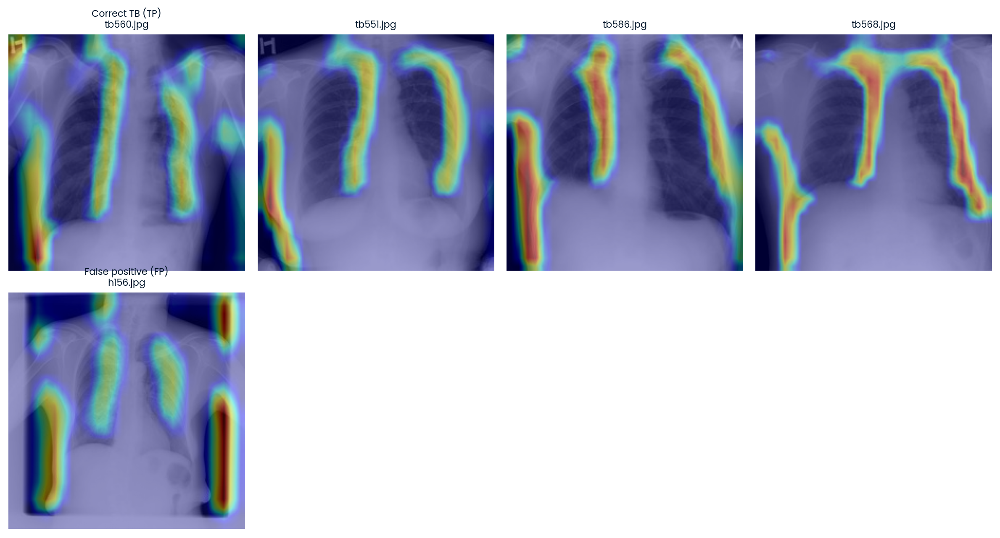

TP shown: 4 | FP shown: 1
[border heat] CNN    : 0.545   (uniform reference 0.51)


In [21]:
## Grad-CAM diagnostics — Keras 3 compatible

import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image as kimage


def build_grad_model(model, input_shape, last_conv=None):
    """Returns a model mapping input -> [last conv feature map, prediction]."""
    if isinstance(model, tf.keras.Sequential):
        inp = tf.keras.Input(shape=input_shape)
        x, conv_out = inp, None
        for l in model.layers:
            x = l(x)
            if isinstance(l, layers.Conv2D) and (last_conv is None or l.name == last_conv):
                conv_out = x
        if conv_out is None:
            raise ValueError("no Conv2D layer found in the Sequential model")
        return tf.keras.Model(inp, [conv_out, x])

    # Functional model (ResNet): graph is intact
    if last_conv is None:
        last_conv = [l.name for l in model.layers if isinstance(l, layers.Conv2D)][-1]
    return tf.keras.Model(model.inputs, [model.get_layer(last_conv).output, model.output])


def cam_from(grad_model, batch):
    """Grad-CAM heatmap, resized to IMG_SIZE, normalized to 0..1."""
    with tf.GradientTape() as tape:
        conv_out, pred = grad_model(batch)
        loss = pred[:, 0]
    grads = tape.gradient(loss, conv_out)
    cam = tf.squeeze(conv_out[0] @ tf.reduce_mean(grads, axis=(0, 1, 2))[..., None])
    cam = tf.maximum(cam, 0) / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()


def cnn_load(img_path):
    """CNN input: grayscale + /255 (NOT preprocess_input)."""
    raw = kimage.img_to_array(
        kimage.load_img(img_path, target_size=IMG_SIZE, color_mode="grayscale"))
    return raw[..., 0], np.expand_dims(raw / 255.0, 0)


# Panel: correct TB vs false positives (CNN)

cnn_m0 = tf.keras.models.load_model("baseline_fold0.keras", compile=False)
gm_cnn = build_grad_model(cnn_m0, (*IMG_SIZE, 1))

paths = test_df["filename"].values
tp_idx = np.where((cnn_y_true == 1) & (cnn_y_pred == 1))[0][:4]
fp_idx = np.where((cnn_y_true == 0) & (cnn_y_pred == 1))[0][:4]

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4), squeeze=False)
for r, (title, idxs) in enumerate([("Correct TB (TP)", tp_idx), ("False positive (FP)", fp_idx)]):
    for c in range(4):
        ax = axes[r][c]; ax.axis("off")
        if c >= len(idxs):
            continue
        raw, batch = cnn_load(paths[idxs[c]])
        ax.imshow(raw, cmap="gray")
        ax.imshow(cam_from(gm_cnn, batch), cmap="jet", alpha=0.4)
        ax.set_title((title + "\n" if c == 0 else "") + os.path.basename(paths[idxs[c]]), fontsize=8)
fig.tight_layout(); fig.savefig("gradcam_panel_cnn.png", dpi=130, bbox_inches="tight"); plt.show()
print(f"TP shown: {len(tp_idx)} | FP shown: {len(fp_idx)}")


# Border-heat score
# Share of Grad-CAM mass in the outer 15% frame, averaged over TB test images.
# A uniform map scores ~0.51. Much higher -> attention on corners/markers.
# Much lower -> attention pulled into the lung fields.

def border_fraction(heat, margin=0.15):
    h, w = heat.shape
    mh, mw = int(h * margin), int(w * margin)
    mask = np.ones_like(heat, dtype=bool)
    mask[mh:h - mh, mw:w - mw] = False
    return float(heat[mask].sum() / (heat.sum() + 1e-8))


tb_paths = test_df[test_df.label_idx == 1].filename.values[:20]

cnn_scores = [border_fraction(cam_from(gm_cnn, cnn_load(p)[1])) for p in tb_paths]
print(f"[border heat] CNN    : {np.mean(cnn_scores):.3f}   (uniform reference 0.51)")

ResNet Grad-CAM layer: conv5_block3_out


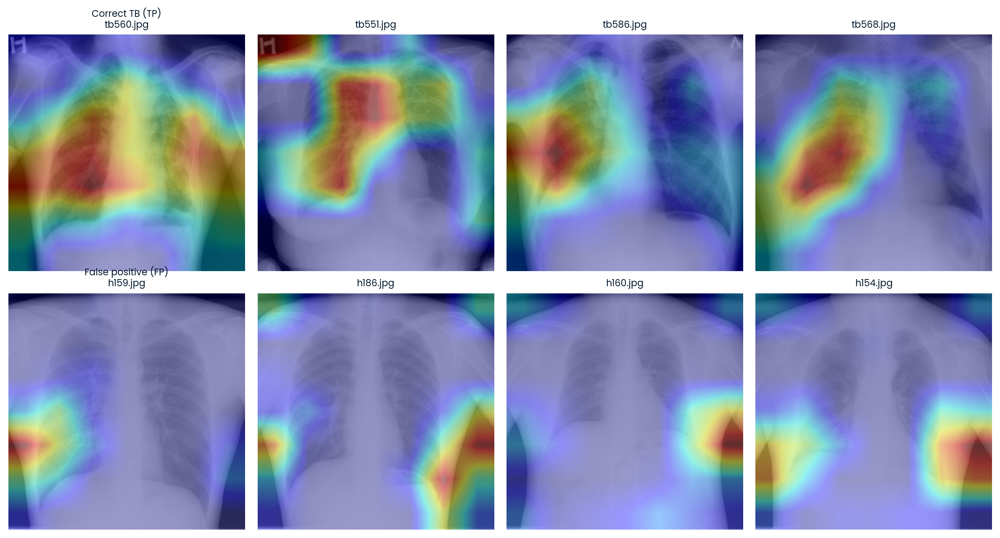

saved gradcam_panel_resnet.png | TP shown: 4 | FP shown: 4
[border heat] ResNet : 0.379   (uniform reference 0.51)


In [22]:
# Grad-CAM diagnostics — ResNet50
# Mirrors the CNN diagnostics cell: model, grad model, TP/FP panel, border-heat score.
# Uses the ResNet input pipeline (rgb + preprocess_input) — feeding it the CNN's
# grayscale/rescale input would produce meaningless maps without raising an error.
# Needs build_grad_model, cam_from, border_fraction, tb_paths from the CNN cell.


from tensorflow.keras.preprocessing import image as kimage
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_pp

res_m0 = tf.keras.models.load_model("best_model_fold0.keras", compile=False)

try:                                    # preferred: post-activation block output
    RESNET_LAST_CONV = res_m0.get_layer("conv5_block3_out").name
except Exception:                       # fallback: last Conv2D in the graph
    RESNET_LAST_CONV = [l.name for l in res_m0.layers
                        if isinstance(l, layers.Conv2D)][-1]
print("ResNet Grad-CAM layer:", RESNET_LAST_CONV)

gm_res = build_grad_model(res_m0, (*IMG_SIZE, 3), last_conv=RESNET_LAST_CONV)


def resnet_load(p):
    """ResNet input: rgb + preprocess_input. Returns (display image, model batch)."""
    raw = kimage.img_to_array(kimage.load_img(p, target_size=IMG_SIZE))
    return raw[..., 0], np.expand_dims(resnet_pp(raw.copy()), 0)



# Panel: correct TB vs false positives

r_true, r_pred = np.asarray(y_test, int), np.asarray(y_pred, int)
paths = test_df["filename"].values
tp_idx = np.where((r_true == 1) & (r_pred == 1))[0][:4]
fp_idx = np.where((r_true == 0) & (r_pred == 1))[0][:4]

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4), squeeze=False)
for r, (title, idxs) in enumerate([("Correct TB (TP)", tp_idx),
                                   ("False positive (FP)", fp_idx)]):
    for c in range(4):
        ax = axes[r][c]; ax.axis("off")
        if c >= len(idxs):
            continue
        raw, batch = resnet_load(paths[idxs[c]])
        ax.imshow(raw, cmap="gray")
        ax.imshow(cam_from(gm_res, batch), cmap="jet", alpha=0.4)
        ax.set_title((title + "\n" if c == 0 else "") +
                     os.path.basename(paths[idxs[c]]), fontsize=8)

fig.tight_layout()
fig.savefig("gradcam_panel_resnet.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"saved gradcam_panel_resnet.png | TP shown: {len(tp_idx)} | FP shown: {len(fp_idx)}")



# Border-heat score
# Share of Grad-CAM mass in the outer 15% frame, averaged over TB test images.
# A uniform map scores ~0.51; lower means attention pulled into the lung fields.

res_scores = [border_fraction(cam_from(gm_res, resnet_load(p)[1])) for p in tb_paths]
print(f"[border heat] ResNet : {np.mean(res_scores):.3f}   (uniform reference 0.51)")


In [23]:
def heat_intensity_corr(heat, raw):
    """Pearson r between Grad-CAM heat and pixel brightness.
       Bright = bone / soft tissue, dark = aerated lung."""
    h, r = heat.ravel(), raw.ravel().astype(float)
    if h.std() < 1e-8 or r.std() < 1e-8:
        return np.nan
    return float(np.corrcoef(h, r)[0, 1])


cnn_corr, res_corr = [], []
for p in tb_paths:
    raw_c, batch_c = cnn_load(p)
    cnn_corr.append(heat_intensity_corr(cam_from(gm_cnn, batch_c), raw_c))
    raw_r, batch_r = resnet_load(p)
    res_corr.append(heat_intensity_corr(cam_from(gm_res, batch_r), raw_r))

print(f"\n[heat vs brightness] CNN    : {np.nanmean(cnn_corr):+.3f}")
print(f"[heat vs brightness] ResNet : {np.nanmean(res_corr):+.3f}")
print("  strongly positive -> attention on bone / contour (artifact-like)")
print("  near zero or negative -> attention inside the lung fields")


[heat vs brightness] CNN    : -0.209
[heat vs brightness] ResNet : -0.447
  strongly positive -> attention on bone / contour (artifact-like)
  near zero or negative -> attention inside the lung fields


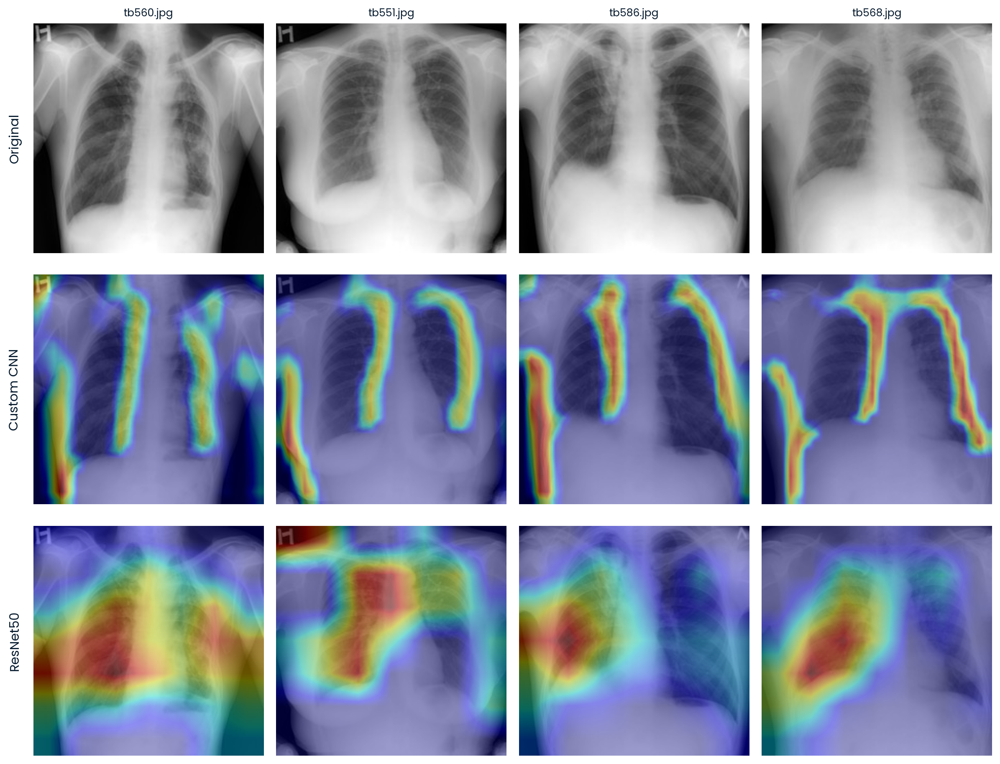

saved gradcam_side_by_side.png | 4 cases


In [24]:
# Grad-CAM side by side: CNN vs ResNet50 on the same images
# Same radiograph, both models' attention. Columns are individual TB cases both models
# classified correctly, so the comparison isn't confounded by one model erring.
# Needs gm_cnn / cnn_load and gm_res / resnet_load from the diagnostics cells.
# test predictions, from memory or from disk
try:
    r_true, r_pred = np.asarray(resnet_y_true, int), np.asarray(resnet_y_pred, int)
except NameError:
    t = np.load("test_predictions.npz")
    r_true, r_pred = t["y_test"].astype(int), t["y_pred"].astype(int)

paths = test_df["filename"].values
both_right = np.where((r_true == 1) & (r_pred == 1) &
                      (np.asarray(cnn_y_true, int) == 1) &
                      (np.asarray(cnn_y_pred, int) == 1))[0][:4]
if len(both_right) == 0:                       # fallback: any TB images
    both_right = np.where(r_true == 1)[0][:4]

ncol = len(both_right)
fig, axes = plt.subplots(3, ncol, figsize=(3 * ncol, 9.4), squeeze=False)
row_labels = ["Original", "Custom CNN", "ResNet50"]

for c, i in enumerate(both_right):
    raw_c, batch_c = cnn_load(paths[i])
    raw_r, batch_r = resnet_load(paths[i])

    axes[0][c].imshow(raw_c, cmap="gray")
    axes[0][c].set_title(os.path.basename(paths[i]), fontsize=9)

    axes[1][c].imshow(raw_c, cmap="gray")
    axes[1][c].imshow(cam_from(gm_cnn, batch_c), cmap="jet", alpha=0.4)

    axes[2][c].imshow(raw_r, cmap="gray")
    axes[2][c].imshow(cam_from(gm_res, batch_r), cmap="jet", alpha=0.4)

for r in range(3):
    for c in range(ncol):
        axes[r][c].axis("off")
    axes[r][0].text(-0.08, 0.5, row_labels[r], transform=axes[r][0].transAxes,
                    rotation=90, va="center", ha="center", fontsize=11)

fig.tight_layout()
fig.savefig("gradcam_side_by_side.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"saved gradcam_side_by_side.png | {ncol} cases")


>  **Withdrawn.** Everything in this section was computed on the test folder, which
> turned out to carry a brightness confounder. Kept here because finding that is the
> point of the project — see "How the confounder was found" below.

In [25]:
# Clinical metrics for both models (95% bootstrap CIs)
# Replaces three separate cells: ResNet metrics, the results-saving block, and the CNN
# metrics cell. Helpers are defined once and applied to both models in a loop, so the
# metrics can never drift apart between the two. Each model keeps its own threshold and
# writes to its own files.
# Needs the test predictions of both models; falls back to disk if a block was not run.

import json


def clinical_metrics(yt, ys, yh):
    tn, fp, fn, tp = confusion_matrix(yt, yh, labels=[0, 1]).ravel()
    return {"roc_auc": roc_auc_score(yt, ys), "pr_auc": average_precision_score(yt, ys),
            "sensitivity": tp / (tp + fn) if tp + fn else np.nan,   # recall for TB
            "specificity": tn / (tn + fp) if tn + fp else np.nan,   # recall for Healthy
            "ppv": tp / (tp + fp) if tp + fp else np.nan,           # precision for TB
            "npv": tn / (tn + fn) if tn + fn else np.nan,           # precision for Healthy
            "f1": f1_score(yt, yh, zero_division=0),
            "confmat": (int(tn), int(fp), int(fn), int(tp))}


def bootstrap_ci(yt, ys, thr, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(yt == 1)[0], np.where(yt == 0)[0]
    keys = ["roc_auc", "sensitivity", "specificity", "ppv", "npv"]
    acc = {k: [] for k in keys}
    for _ in range(n):
        idx = np.concatenate([rng.choice(pos, len(pos), True),
                              rng.choice(neg, len(neg), True)])
        m = clinical_metrics(yt[idx], ys[idx], (ys[idx] >= thr).astype(int))
        for k in keys:
            acc[k].append(m[k])
    return {k: [float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))]
            for k, v in acc.items()}


# --- gather both models' predictions ----------------------------------------
entries = {}
try:
    entries["ResNet50"] = (np.asarray(y_test, float), np.asarray(test_prob, float),
                           np.asarray(y_pred, int), float(FIXED_THRESHOLD),
                           "test_results.json", "test_predictions.npz")
except NameError:
    t = np.load("test_predictions.npz")
    entries["ResNet50"] = (t["y_test"].astype(float), t["test_prob"].astype(float),
                           t["y_pred"].astype(int),
                           float(json.load(open("test_results.json"))["fixed_threshold"]),
                           "test_results.json", "test_predictions.npz")

entries["Custom CNN"] = (np.asarray(cnn_y_true, float), np.asarray(cnn_y_probs, float),
                         np.asarray(cnn_y_pred, int), float(CNN_FIXED_THRESHOLD),
                         "cnn_test_results.json", "cnn_test_predictions.npz")


# --- evaluate, report, save --------------------------------------------------
ORDER = ["roc_auc", "pr_auc", "sensitivity", "specificity", "ppv", "npv", "f1"]
summary, stored = {}, {}

for name, (yt, ys, yh, thr, json_path, npz_path) in entries.items():
    res = clinical_metrics(yt, ys, yh)
    ci = bootstrap_ci(yt, ys, thr)
    stored[name] = (res, ci)

    tn, fp, fn, tp = res["confmat"]
    print(f"\n=== {name} (n={len(yt)}, threshold {thr:.3f}) ===")
    print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
    for k in ORDER:
        if k in ci:
            print(f"  {k:12s}: {res[k]:.3f}  [{ci[k][0]:.3f}-{ci[k][1]:.3f}]")
        else:
            print(f"  {k:12s}: {res[k]:.3f}")

    json.dump({"fixed_threshold": thr,
               "point": {k: float(res[k]) for k in ORDER},
               "ci95": ci,
               "confusion_matrix": dict(zip(["tn", "fp", "fn", "tp"], res["confmat"])),
               "n_test": int(len(yt))},
              open(json_path, "w"), indent=2)
    np.savez(npz_path, test_prob=ys, y_test=yt, y_pred=yh)

    summary[name] = {k: (f"{res[k]:.2f} [{ci[k][0]:.2f}-{ci[k][1]:.2f}]" if k in ci
                         else f"{res[k]:.2f}") for k in ORDER}

table = pd.DataFrame(summary).T
table.to_csv("model_comparison_clinical.csv")
table



=== ResNet50 (n=100, threshold 0.147) ===
TN=43 FP=7 FN=3 TP=47
  roc_auc     : 0.970  [0.938-0.993]
  pr_auc      : 0.971
  sensitivity : 0.940  [0.880-1.000]
  specificity : 0.860  [0.760-0.940]
  ppv         : 0.870  [0.790-0.942]
  npv         : 0.935  [0.865-1.000]
  f1          : 0.904

=== Custom CNN (n=100, threshold 0.436) ===
TN=49 FP=1 FN=4 TP=46
  roc_auc     : 0.984  [0.950-1.000]
  pr_auc      : 0.974
  sensitivity : 0.920  [0.840-0.980]
  specificity : 0.980  [0.940-1.000]
  ppv         : 0.979  [0.936-1.000]
  npv         : 0.925  [0.857-0.980]
  f1          : 0.948


,roc_auc,pr_auc,sensitivity,specificity,ppv,npv,f1
ResNet50,0.97 [0.94-0.99],0.97,0.94 [0.88-1.00],0.86 [0.76-0.94],0.87 [0.79-0.94],0.93 [0.87-1.00],0.90
Custom CNN,0.98 [0.95-1.00],0.97,0.92 [0.84-0.98],0.98 [0.94-1.00],0.98 [0.94-1.00],0.92 [0.86-0.98],0.95


>  **Withdrawn.** Everything in this section was computed on the test folder, which
> turned out to carry a brightness confounder. Kept here because finding that is the
> point of the project — see "How the confounder was found" below.

In [26]:
# Paired bootstrap: is the CNN-vs-ResNet difference real?
# Overlapping confidence intervals are NOT a test of the difference between two
# models. The correct comparison resamples the SAME test images for both models and
# builds a CI on the difference itself. If that interval excludes 0, the difference
# is significant at the 5% level.
# Each model keeps its own threshold, since each was tuned separately on its own OOF.
# Needs clinical_metrics (defined in the CNN metrics cell).

import json

# --- collect both models' predictions on the same images --------------------
y_cnn   = np.asarray(cnn_y_true, dtype=float)
p_cnn   = np.asarray(cnn_y_probs, dtype=float)
thr_cnn = float(CNN_FIXED_THRESHOLD)

try:
    y_res, p_res = np.asarray(resnet_y_true, float), np.asarray(resnet_y_probs, float)
    thr_res = float(RESNET_FIXED_THRESHOLD)
except NameError:
    t = np.load("test_predictions.npz")
    y_res, p_res = t["y_test"].astype(float), t["test_prob"].astype(float)
    thr_res = float(json.load(open("test_results.json"))["fixed_threshold"])

assert len(y_cnn) == len(y_res) and np.array_equal(y_cnn, y_res), \
    "The two models were evaluated on different images or in a different order."
y_true = y_cnn


# --- paired bootstrap on the difference -------------------------------------
def paired_bootstrap(y_true, pa, thr_a, pb, thr_b, n=2000, seed=SEED):
    """Same resampled indices for both models -> CI on (model A - model B)."""
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
    keys = ["roc_auc", "sensitivity", "specificity", "ppv", "npv"]
    diffs = {k: [] for k in keys}
    for _ in range(n):
        idx = np.concatenate([rng.choice(pos, len(pos), True),
                              rng.choice(neg, len(neg), True)])
        yt = y_true[idx]
        ma = clinical_metrics(yt, pa[idx], (pa[idx] >= thr_a).astype(int))
        mb = clinical_metrics(yt, pb[idx], (pb[idx] >= thr_b).astype(int))
        for k in keys:
            diffs[k].append(ma[k] - mb[k])
    return diffs


diffs = paired_bootstrap(y_true, p_cnn, thr_cnn, p_res, thr_res)

obs_cnn = clinical_metrics(y_true, p_cnn, (p_cnn >= thr_cnn).astype(int))
obs_res = clinical_metrics(y_true, p_res, (p_res >= thr_res).astype(int))

rows = []
print(f"Paired bootstrap, n={len(y_true)} images, 2000 resamples")
print("Difference = CNN - ResNet\n")
for k in ["roc_auc", "sensitivity", "specificity", "ppv", "npv"]:
    d = np.array(diffs[k], dtype=float)
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    point = obs_cnn[k] - obs_res[k]
    sig = "significant" if (lo > 0 or hi < 0) else "not significant"
    print(f"  {k:12s}: CNN {obs_cnn[k]:.3f} | ResNet {obs_res[k]:.3f} | "
          f"diff {point:+.3f} [{lo:+.3f}, {hi:+.3f}]  -> {sig}")
    rows.append({"metric": k, "cnn": round(float(obs_cnn[k]), 3),
                 "resnet": round(float(obs_res[k]), 3), "difference": round(float(point), 3),
                 "ci95_low": round(float(lo), 3), "ci95_high": round(float(hi), 3),
                 "significant": sig == "significant"})

print("\nNote: five metrics are compared at once, so an isolated borderline result")
print("should be read with caution (no multiplicity correction applied).")

paired = pd.DataFrame(rows).set_index("metric")
paired.to_csv("model_comparison_paired.csv")
paired

Paired bootstrap, n=100 images, 2000 resamples
Difference = CNN - ResNet

  roc_auc     : CNN 0.984 | ResNet 0.970 | diff +0.014 [-0.010, +0.040]  -> not significant
  sensitivity : CNN 0.920 | ResNet 0.940 | diff -0.020 [-0.120, +0.060]  -> not significant
  specificity : CNN 0.980 | ResNet 0.860 | diff +0.120 [+0.040, +0.220]  -> significant
  ppv         : CNN 0.979 | ResNet 0.870 | diff +0.108 [+0.036, +0.185]  -> significant
  npv         : CNN 0.925 | ResNet 0.935 | diff -0.010 [-0.093, +0.069]  -> not significant

Note: five metrics are compared at once, so an isolated borderline result
should be read with caution (no multiplicity correction applied).


,cnn,resnet,difference,ci95_low,ci95_high,significant
metric,,,,,,
roc_auc,0.984,0.970,0.014,-0.010,0.040,False
sensitivity,0.920,0.940,-0.020,-0.120,0.060,False
specificity,0.980,0.860,0.120,0.040,0.220,True
ppv,0.979,0.870,0.108,0.036,0.185,True
npv,0.925,0.935,-0.010,-0.093,0.069,False


>  **Withdrawn.** Everything in this section was computed on the test folder, which
> turned out to carry a brightness confounder. Kept here because finding that is the
> point of the project — see "How the confounder was found" below.

Agreement: 89/100 images (89.0%)
Disagreements: 11
  CNN correct, ResNet wrong : 8
  ResNet correct, CNN wrong : 3
Both models wrong (agreeing): 2


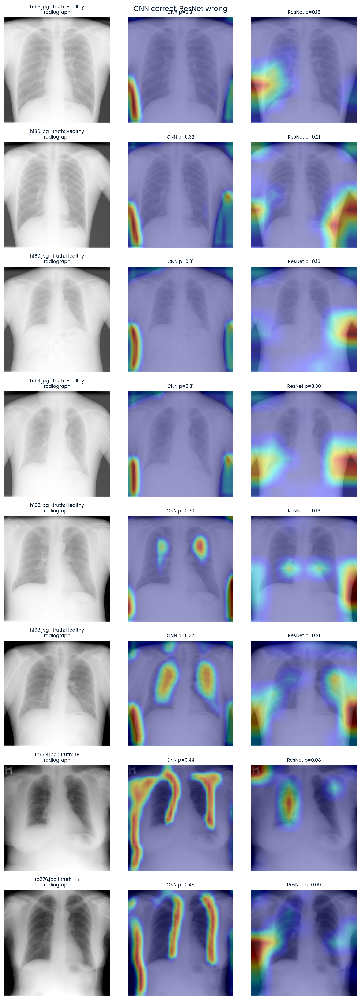

saved disagree_cnn_right.png


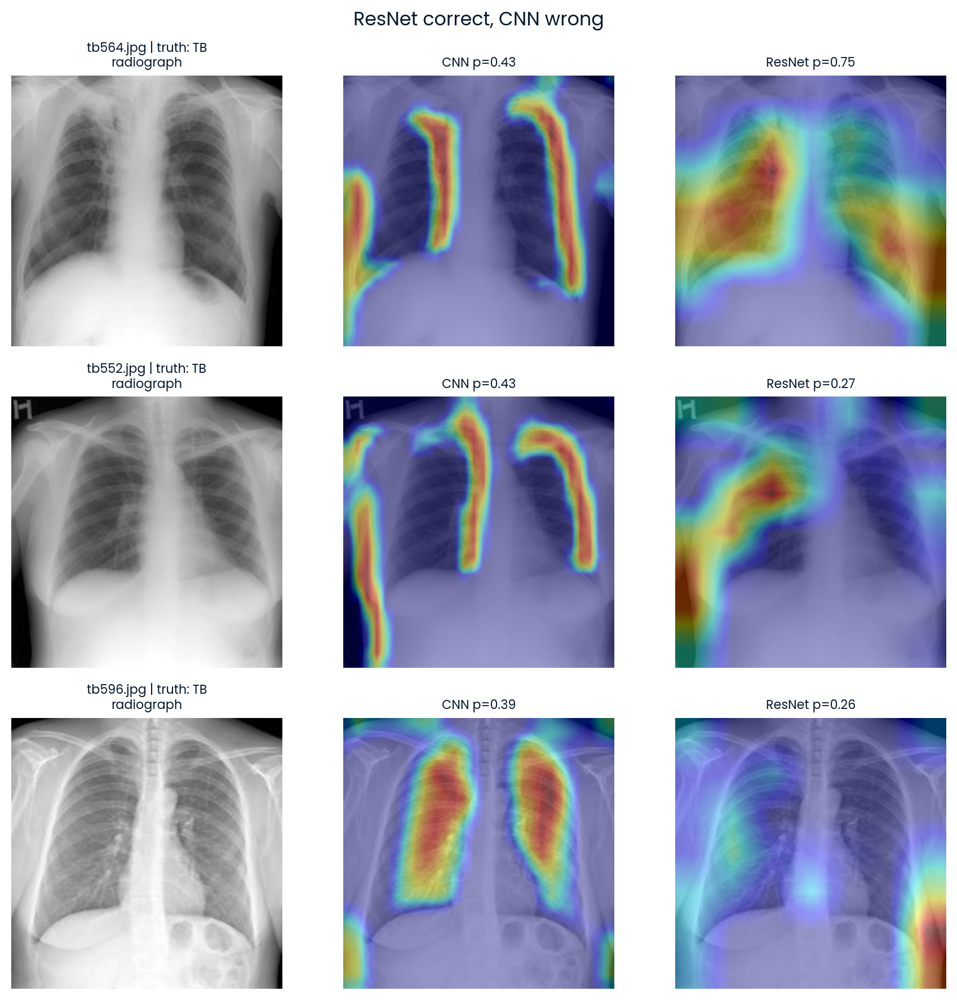

saved disagree_resnet_right.png


In [27]:
# Disagreement analysis: where the two models differ
# Tests the radiologist's observation that the models may divide the work between
# them. Cases where both models agree carry no information about that; the cases
# where they differ are the ones to review.
#
# For each disagreement the figure shows the radiograph plus both attention maps,
# labelled with the ground truth and each model's probability.
# Needs gm_cnn/cnn_load, gm_res/resnet_load, cam_from from the Grad-CAM cells.

import json

# --- predictions of both models (from memory, or from disk) -----------------
try:
    truth = np.asarray(y_test, int)
    res_pred, res_prob = np.asarray(y_pred, int), np.asarray(test_prob, float)
except NameError:
    t = np.load("test_predictions.npz")
    truth = t["y_test"].astype(int)
    res_pred, res_prob = t["y_pred"].astype(int), t["test_prob"].astype(float)

cnn_pred, cnn_prob = np.asarray(cnn_y_pred, int), np.asarray(cnn_y_probs, float)
paths = test_df["filename"].values

assert len(truth) == len(cnn_pred) == len(res_pred), "prediction arrays differ in length"

# --- who is right where ------------------------------------------------------
agree      = cnn_pred == res_pred
disagree   = np.where(~agree)[0]
cnn_right  = disagree[cnn_pred[disagree] == truth[disagree]]
res_right  = disagree[res_pred[disagree] == truth[disagree]]
both_wrong = np.where(agree & (cnn_pred != truth))[0]

print(f"Agreement: {agree.sum()}/{len(truth)} images ({agree.mean():.1%})")
print(f"Disagreements: {len(disagree)}")
print(f"  CNN correct, ResNet wrong : {len(cnn_right)}")
print(f"  ResNet correct, CNN wrong : {len(res_right)}")
print(f"Both models wrong (agreeing): {len(both_wrong)}")

summary = pd.DataFrame([
    {"file": os.path.basename(paths[i]),
     "truth": "TB" if truth[i] else "Healthy",
     "cnn_prob": round(float(cnn_prob[i]), 3),
     "cnn_says": "TB" if cnn_pred[i] else "Healthy",
     "resnet_prob": round(float(res_prob[i]), 3),
     "resnet_says": "TB" if res_pred[i] else "Healthy",
     "correct": "CNN" if i in set(cnn_right) else "ResNet"}
    for i in disagree])
summary.to_csv("model_disagreements.csv", index=False)
summary


# Attention maps on the disagreement cases
# One row per case: radiograph, CNN attention, ResNet attention.
# Review these against the hypothesis — does the model that got it right show
# attention on the finding type it is supposed to be better at?

def disagreement_figure(idxs, title, save_path):
    if len(idxs) == 0:
        print(f"{title}: none")
        return
    n = len(idxs)
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n), squeeze=False)
    for r, i in enumerate(idxs):
        raw_c, batch_c = cnn_load(paths[i])
        raw_r, batch_r = resnet_load(paths[i])
        for c, (img, cam, lbl) in enumerate([
                (raw_c, None, "radiograph"),
                (raw_c, cam_from(gm_cnn, batch_c), f"CNN p={cnn_prob[i]:.2f}"),
                (raw_r, cam_from(gm_res, batch_r), f"ResNet p={res_prob[i]:.2f}")]):
            ax = axes[r][c]; ax.axis("off")
            ax.imshow(img, cmap="gray")
            if cam is not None:
                ax.imshow(cam, cmap="jet", alpha=0.4)
            head = f"{os.path.basename(paths[i])} | truth: {'TB' if truth[i] else 'Healthy'}\n" if c == 0 else ""
            ax.set_title(head + lbl, fontsize=8)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()
    print("saved", save_path)


disagreement_figure(cnn_right, "CNN correct, ResNet wrong", "disagree_cnn_right.png")
disagreement_figure(res_right, "ResNet correct, CNN wrong", "disagree_resnet_right.png")


>  **Withdrawn.** Everything in this section was computed on the test folder, which
> turned out to carry a brightness confounder. Kept here because finding that is the
> point of the project — see "How the confounder was found" below.

In [28]:
# Is the disagreement about attention, or about threshold placement?
# The two models run at very different cutoffs (ResNet 0.147, CNN 0.436), and a low
# cutoff produces false positives on its own. So part of the 8-vs-3 split may be
# calibration rather than what the models actually see.
# Two checks:
#   1. matched-sensitivity thresholds, fitted on OOF (never on the test set), so both
#      models are compared at the same operating point;
#   2. confident vs borderline errors — an error made at p=0.20 just past a 0.147
#      cutoff says little about attention; an error made at p=0.80 does.
#
# This is exploratory analysis for interpretation, not a second set of reported
# metrics — the headline numbers stay the ones fitted on OOF earlier.

from sklearn.metrics import roc_curve

# --- OOF predictions of both models -----------------------------------------
d_res = np.load("oof.npz")
res_oof_true, res_oof_prob = d_res["oof_true"], d_res["oof_prob"]
d_cnn = np.load("baseline_oof.npz")
cnn_oof_true, cnn_oof_prob = d_cnn["oof_true"], d_cnn["oof_prob"]


def threshold_for_sensitivity(y_true, y_probs, target=0.92):
    """Highest threshold that still reaches `target` sensitivity (max specificity)."""
    fpr, tpr, thr = roc_curve(y_true, y_probs)
    ok = tpr >= target
    return float(thr[ok][0]) if ok.any() else 0.5


TARGET_SENS = 0.92
thr_cnn_m = threshold_for_sensitivity(cnn_oof_true, cnn_oof_prob, TARGET_SENS)
thr_res_m = threshold_for_sensitivity(res_oof_true, res_oof_prob, TARGET_SENS)
print(f"Matched thresholds at sensitivity >= {TARGET_SENS} (fitted on OOF):")
print(f"  CNN    : {thr_cnn_m:.3f}   (own threshold was {CNN_FIXED_THRESHOLD:.3f})")
print(f"  ResNet : {thr_res_m:.3f}   (own threshold was {FIXED_THRESHOLD:.3f})")

cnn_pred_m = (cnn_prob >= thr_cnn_m).astype(int)
res_pred_m = (res_prob >= thr_res_m).astype(int)

for name, pred in [("CNN", cnn_pred_m), ("ResNet", res_pred_m)]:
    tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0, 1]).ravel()
    print(f"  {name:7s} at matched threshold: TN={tn} FP={fp} FN={fn} TP={tp}")

dis_m = np.where(cnn_pred_m != res_pred_m)[0]
cnn_right_m = dis_m[cnn_pred_m[dis_m] == truth[dis_m]]
res_right_m = dis_m[res_pred_m[dis_m] == truth[dis_m]]
print(f"\nAt matched thresholds: {len(dis_m)} disagreements "
      f"(CNN right {len(cnn_right_m)}, ResNet right {len(res_right_m)})")
print(f"Own thresholds gave:   {len(disagree)} disagreements "
      f"(CNN right {len(cnn_right)}, ResNet right {len(res_right)})")


# Confident vs borderline errors
# Margin = how far the wrong model's probability sat from its own cutoff.

rows = []
for i in disagree:
    cnn_wrong = cnn_pred[i] != truth[i]
    p    = cnn_prob[i] if cnn_wrong else res_prob[i]
    thr  = CNN_FIXED_THRESHOLD if cnn_wrong else FIXED_THRESHOLD
    rows.append({"file": os.path.basename(paths[i]),
                 "truth": "TB" if truth[i] else "Healthy",
                 "wrong_model": "CNN" if cnn_wrong else "ResNet",
                 "its_prob": round(float(p), 3),
                 "its_threshold": round(float(thr), 3),
                 "margin": round(float(abs(p - thr)), 3),
                 "cnn_prob": round(float(cnn_prob[i]), 3),
                 "resnet_prob": round(float(res_prob[i]), 3)})

margins = pd.DataFrame(rows).sort_values("margin", ascending=False)
margins.to_csv("disagreement_margins.csv", index=False)

BORDERLINE = 0.15
confident = margins[margins["margin"] >= BORDERLINE]
print(f"\nConfident errors (margin >= {BORDERLINE}): {len(confident)} of {len(margins)}")
print("These are the informative cases for the radiologist review;")
print("the rest sit close to their cutoff and reflect calibration more than attention.")
margins


Matched thresholds at sensitivity >= 0.92 (fitted on OOF):
  CNN    : 0.431   (own threshold was 0.436)
  ResNet : 0.112   (own threshold was 0.147)
  CNN     at matched threshold: TN=49 FP=1 FN=3 TP=47
  ResNet  at matched threshold: TN=40 FP=10 FN=2 TP=48

At matched thresholds: 14 disagreements (CNN right 11, ResNet right 3)
Own thresholds gave:   11 disagreements (CNN right 8, ResNet right 3)

Confident errors (margin >= 0.15): 1 of 11
These are the informative cases for the radiologist review;
the rest sit close to their cutoff and reflect calibration more than attention.


,file,truth,wrong_model,its_prob,its_threshold,margin,cnn_prob,resnet_prob
3,h154.jpg,Healthy,ResNet,0.303,0.147,0.155,0.310,0.303
7,tb553.jpg,TB,ResNet,0.077,0.147,0.070,0.442,0.077
5,h198.jpg,Healthy,ResNet,0.214,0.147,0.067,0.373,0.214
1,h186.jpg,Healthy,ResNet,0.213,0.147,0.066,0.323,0.213
10,tb576.jpg,TB,ResNet,0.087,0.147,0.061,0.449,0.087
9,tb596.jpg,TB,CNN,0.392,0.436,0.044,0.392,0.256
2,h160.jpg,Healthy,ResNet,0.161,0.147,0.013,0.309,0.161
0,h159.jpg,Healthy,ResNet,0.159,0.147,0.011,0.310,0.159
4,h163.jpg,Healthy,ResNet,0.158,0.147,0.010,0.304,0.158
6,tb564.jpg,TB,CNN,0.430,0.436,0.006,0.430,0.745


> ⚠️ **Withdrawn.** Built on test-folder predictions.

Rather than combining the models into a single classifier, the two are used as a triage
filter: agreement decides the case automatically, disagreement routes it to a radiologist.
On the test folder this referred 11% of images and left 1 of 50 TB cases undetected among
the automatically decided ones — which looked better than either model alone at the same
workload.

The idea survives the confounder; the numbers don't. Re-run on out-of-fold predictions the
same rule refers 33% of images, which is a very different proposition.

>  **Withdrawn.** Everything in this section was computed on the test folder, which
> turned out to carry a brightness confounder. Kept here because finding that is the
> point of the project — see "How the confounder was found" below.

In [29]:
# Two models as a triage filter
# Rule: when both models agree, the case is decided automatically; when they disagree,
# it goes to a radiologist. The rule has no free parameters of its own — both thresholds
# were already fixed on OOF — so nothing here is tuned on the test set.
# What matters for such a system:
#   * referral rate — how much human work it creates
#   * accuracy on the auto-decided part — errors that pass through silently
#   * missed TB among the auto-decided — the safety-critical number
# Compared against the fair alternative: one model alone, referring its least
# confident cases at the same workload.

agree_mask = cnn_pred == res_pred
auto  = np.where(agree_mask)[0]           # decided automatically
refer = np.where(~agree_mask)[0]          # sent to the radiologist
auto_pred = cnn_pred[auto]                # both agree, so either model's call
auto_true = truth[auto]

tn, fp, fn, tp = confusion_matrix(auto_true, auto_pred, labels=[0, 1]).ravel()
tb_total = int((truth == 1).sum())

print("=== Two-model triage ===")
print(f"Referred to radiologist : {len(refer)}/{len(truth)} ({len(refer)/len(truth):.0%})")
print(f"Decided automatically   : {len(auto)}")
print(f"  accuracy on those     : {(tn + tp) / len(auto):.3f}  (TN={tn} FP={fp} FN={fn} TP={tp})")
print(f"  sensitivity           : {tp / (tp + fn):.3f}")
print(f"  specificity           : {tn / (tn + fp):.3f}")
print(f"  TB missed silently    : {fn} of {tb_total} TB cases in the set")
print(f"  false alarms passed   : {fp}")
print(f"TB cases sent for review: {int((truth[refer] == 1).sum())} of {len(refer)} referrals")


# Fair comparison: a single model referring its least confident cases
# If one model plus an uncertainty band does just as well at the same workload,
# the second model is not earning its place.

def uncertainty_triage(prob, thr, n_refer, name):
    order = np.argsort(np.abs(prob - thr))          # closest to the cutoff first
    refer_i = order[:n_refer]
    auto_i = np.setdiff1d(np.arange(len(prob)), refer_i)
    pred = (prob[auto_i] >= thr).astype(int)
    a_tn, a_fp, a_fn, a_tp = confusion_matrix(truth[auto_i], pred, labels=[0, 1]).ravel()
    print(f"\n=== {name} alone, referring its {n_refer} least confident ===")
    print(f"  accuracy on auto part : {(a_tn + a_tp) / len(auto_i):.3f} "
          f"(TN={a_tn} FP={a_fp} FN={a_fn} TP={a_tp})")
    print(f"  TB missed silently    : {a_fn}")
    return {"missed_tb": int(a_fn), "false_alarms": int(a_fp),
            "accuracy": float((a_tn + a_tp) / len(auto_i))}


single_cnn = uncertainty_triage(cnn_prob, CNN_FIXED_THRESHOLD, len(refer), "CNN")
single_res = uncertainty_triage(res_prob, FIXED_THRESHOLD, len(refer), "ResNet")

triage_summary = pd.DataFrame({
    "Two-model disagreement": {"referrals": len(refer), "missed_tb": int(fn),
                               "false_alarms": int(fp),
                               "accuracy_auto": round((tn + tp) / len(auto), 3)},
    "CNN + uncertainty band": {"referrals": len(refer), **single_cnn,
                               "accuracy_auto": round(single_cnn["accuracy"], 3)},
    "ResNet + uncertainty band": {"referrals": len(refer), **single_res,
                                  "accuracy_auto": round(single_res["accuracy"], 3)},
}).T[["referrals", "missed_tb", "false_alarms", "accuracy_auto"]]
triage_summary.to_csv("triage_comparison.csv")
triage_summary


=== Two-model triage ===
Referred to radiologist : 11/100 (11%)
Decided automatically   : 89
  accuracy on those     : 0.978  (TN=43 FP=1 FN=1 TP=44)
  sensitivity           : 0.978
  specificity           : 0.977
  TB missed silently    : 1 of 50 TB cases in the set
  false alarms passed   : 1
TB cases sent for review: 5 of 11 referrals

=== CNN alone, referring its 11 least confident ===
  accuracy on auto part : 0.966 (TN=48 FP=1 FN=2 TP=38)
  TB missed silently    : 2

=== ResNet alone, referring its 11 least confident ===
  accuracy on auto part : 0.933 (TN=38 FP=4 FN=2 TP=45)
  TB missed silently    : 2


,referrals,missed_tb,false_alarms,accuracy_auto
Two-model disagreement,11.0,1.0,1.0,0.978
CNN + uncertainty band,11.0,2.0,1.0,0.966
ResNet + uncertainty band,11.0,2.0,4.0,0.933


In [30]:
# Model C — DenseNet121, trained in resumable chunks
# A third architecture for the triage scheme. Dense connectivity instead of residual,
# ~8M parameters, so its errors should be less correlated with ResNet50's than another
# residual network would be.
# Training is split across sessions: set DENSE_FOLDS_TO_RUN, run, close the session,
# come back and run the next chunk. Already-trained folds are skipped, and each fold's
# out-of-fold predictions are written to their own file so nothing is lost when the
# session ends. A separate assembly cell stitches them into dense_oof.npz.
# All names are prefixed dense_ / DENSE_ — nothing here touches the frozen CNN or
# ResNet files.

# DenseNet config

from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input as dense_pp

DENSE_EPOCHS_HEAD     = 30
DENSE_EPOCHS_FINETUNE = 30
DENSE_BATCH           = 16
DENSE_UNFREEZE_PREFIX = "conv5"          # last dense block
DENSE_LAST_CONV       = "conv5_block16_concat"

# Which folds to train in THIS session, e.g. [0, 1] then [2, 3] then [4]
DENSE_FOLDS_TO_RUN = [4]

In [31]:
# Generators and model
# DenseNet has its own preprocess_input — it cannot share ResNet's datagens.

dense_train_datagen = ImageDataGenerator(
    preprocessing_function=dense_pp,
    rotation_range=10, width_shift_range=0.08, height_shift_range=0.08,
    zoom_range=0.12, brightness_range=(0.85, 1.15),
    horizontal_flip=True, fill_mode="constant", cval=0)
dense_val_datagen = ImageDataGenerator(preprocessing_function=dense_pp)


def dense_make_gen(datagen, frame, shuffle, batch):
    return datagen.flow_from_dataframe(
        frame, x_col="filename", y_col="label", target_size=IMG_SIZE,
        color_mode="rgb", class_mode="binary",
        batch_size=batch, shuffle=shuffle, seed=SEED)


def build_dense(dropout=0.4):
    base = DenseNet121(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    base.trainable = False
    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid", kernel_regularizer=regularizers.l2(1e-4))(x)
    return models.Model(base.input, out), base


def dense_compile(model, lr):
    model.compile(optimizer=AdamW(learning_rate=lr, weight_decay=1e-4),
                  loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
                  metrics=[AUC(name="auc"), AUC(name="pr_auc", curve="PR"),
                           Precision(name="precision"), Recall(name="recall")])
    return model


def dense_unfreeze_top(base, prefix=DENSE_UNFREEZE_PREFIX):
    base.trainable = True
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
        elif not l.name.startswith(prefix):
            l.trainable = False
    print(f"Unfrozen: {sum(l.trainable for l in base.layers)}/{len(base.layers)} (BN frozen)")


def dense_callbacks(ckpt):
    return [EarlyStopping(monitor="val_pr_auc", mode="max", patience=10,
                          restore_best_weights=True, verbose=1),
            ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.3,
                              patience=4, min_lr=1e-7, verbose=1),
            ModelCheckpoint(ckpt, monitor="val_pr_auc", mode="max",
                            save_best_only=True, verbose=0)]

In [32]:
# Training — run this once per chunk, editing DENSE_FOLDS_TO_RUN each time
# The split comes from the same `skf` with the same seed, so folds are identical
# across sessions and identical to the other two models.

for fold, (tr, va) in enumerate(skf.split(df["filename"], df["label_idx"])):
    if fold not in DENSE_FOLDS_TO_RUN:
        continue
    if os.path.exists(f"dense_oof_fold{fold}.npz"):
        print(f"fold {fold}: already done, skipping")
        continue

    print(f"\n{'='*22} DenseNet fold {fold+1}/{N_SPLITS} {'='*22}")
    clear_session(); tf.random.set_seed(SEED + fold)
    g_tr = dense_make_gen(dense_train_datagen,
                          df.iloc[tr].reset_index(drop=True), True, DENSE_BATCH)
    g_va = dense_make_gen(dense_val_datagen,
                          df.iloc[va].reset_index(drop=True), False, 8)
    assert g_tr.class_indices.get("tb") == 1, f"class_indices mismatch: {g_tr.class_indices}"

    dense_model, dense_base = build_dense()
    dense_compile(dense_model, 1e-3)
    dense_model.fit(g_tr, validation_data=g_va, epochs=DENSE_EPOCHS_HEAD,
                    callbacks=dense_callbacks(f"dense_head_fold{fold}.keras"), verbose=2)

    dense_unfreeze_top(dense_base)
    dense_compile(dense_model, 1e-5)
    dense_model.fit(g_tr, validation_data=g_va, epochs=DENSE_EPOCHS_FINETUNE,
                    callbacks=dense_callbacks(f"dense_fold{fold}.keras"), verbose=2)

    g_va.reset()
    prob = dense_model.predict(g_va, verbose=0).ravel()
    # indices are saved with the predictions so the assembly can place them correctly
    np.savez(f"dense_oof_fold{fold}.npz",
             idx=va, prob=prob, true=np.array(g_va.classes).astype(float))
    print(f"fold {fold}: ROC-AUC={roc_auc_score(g_va.classes, prob):.3f}  -> saved")

    del dense_model, dense_base
    clear_session()

done = [f for f in range(N_SPLITS) if os.path.exists(f"dense_oof_fold{f}.npz")]
print(f"\nFolds complete: {done}  |  remaining: {[f for f in range(N_SPLITS) if f not in done]}")

fold 4: already done, skipping

Folds complete: [0, 1, 2, 3, 4]  |  remaining: []


In [33]:
# Assembly — run once, after all five folds exist
# Stitches the per-fold files into full OOF arrays and checks every image is covered
# exactly once.

dense_oof_prob = np.zeros(len(df))
dense_oof_true = np.zeros(len(df))
seen = np.zeros(len(df), dtype=int)

missing = [f for f in range(N_SPLITS) if not os.path.exists(f"dense_oof_fold{f}.npz")]
if missing:
    raise RuntimeError(f"folds not trained yet: {missing} — run those chunks first")

for fold in range(N_SPLITS):
    d = np.load(f"dense_oof_fold{fold}.npz")
    idx = d["idx"]
    dense_oof_prob[idx] = d["prob"]
    dense_oof_true[idx] = d["true"]
    seen[idx] += 1  

assert (seen == 1).all(), f"coverage error: {(seen != 1).sum()} images not covered exactly once"
np.savez("dense_oof.npz", oof_prob=dense_oof_prob, oof_true=dense_oof_true)
print(f"assembled {len(df)} OOF predictions")
print(f"DenseNet OOF ROC-AUC: {roc_auc_score(dense_oof_true, dense_oof_prob):.3f}")

DENSE_FIXED_THRESHOLD = get_fixed_threshold(dense_oof_true, dense_oof_prob)
print(f"DENSE_FIXED_THRESHOLD: {DENSE_FIXED_THRESHOLD:.3f}")

assembled 302 OOF predictions
DenseNet OOF ROC-AUC: 0.795
DENSE_FIXED_THRESHOLD: 0.261


In [34]:
# Choosing the triage rule on OOF (not on the test set)
# Does the third model earn its place? Compares the current two-model rule against
# three-model variants on the out-of-fold predictions — the only place a rule may be
# chosen. Whatever wins here gets ONE run on the test set afterwards.

d_cnn  = np.load("baseline_oof.npz")
d_res  = np.load("oof.npz")
d_den  = np.load("dense_oof.npz")

y = np.asarray(df["label_idx"], int)
for name, d in [("CNN", d_cnn), ("ResNet", d_res), ("DenseNet", d_den)]:
    assert np.array_equal(d["oof_true"].astype(int), y), f"{name} OOF labels are misaligned"

p_cnn, p_res, p_den = d_cnn["oof_prob"], d_res["oof_prob"], d_den["oof_prob"]
v_cnn = (p_cnn >= CNN_FIXED_THRESHOLD).astype(int)
v_res = (p_res >= FIXED_THRESHOLD).astype(int)
v_den = (p_den >= DENSE_FIXED_THRESHOLD).astype(int)

for name, v, p in [("CNN", v_cnn, p_cnn), ("ResNet", v_res, p_res), ("DenseNet", v_den, p_den)]:
    print(f"{name:9s} OOF AUC {roc_auc_score(y, p):.3f} | errors {int((v != y).sum())}/{len(y)}")

# --- does DenseNet rescue anything the other two get wrong? ------------------
both_wrong = (v_cnn != y) & (v_res != y)
rescued = both_wrong & (v_den == y)
print(f"\nCNN and ResNet both wrong on {int(both_wrong.sum())} images; "
      f"DenseNet right on {int(rescued.sum())} of them")
print(f"  of those rescues, TB cases: {int((rescued & (y == 1)).sum())}")


# --- rules -------------------------------------------------------------------
def evaluate_rule(name, decided_mask, decision):
    """decided_mask: handled automatically. decision: the call on those images."""
    auto = np.where(decided_mask)[0]
    if len(auto) == 0:
        return None
    tn, fp, fn, tp = confusion_matrix(y[auto], decision[auto], labels=[0, 1]).ravel()
    row = {"referrals": int(len(y) - len(auto)),
           "referral_rate": round(1 - len(auto) / len(y), 3),
           "missed_tb": int(fn), "false_alarms": int(fp),
           "accuracy_auto": round((tn + tp) / len(auto), 3)}
    print(f"{name:28s} refer {row['referrals']:3d} ({row['referral_rate']:.0%}) | "
          f"missed TB {row['missed_tb']:2d} | FP {row['false_alarms']:2d} | "
          f"acc {row['accuracy_auto']:.3f}")
    return row


votes = v_cnn + v_res + v_den
rows = {}
print("\n--- rules on OOF ---")
rows["Two-model agreement"] = evaluate_rule(
    "Two-model agreement", v_cnn == v_res, v_cnn)
rows["Three-model unanimity"] = evaluate_rule(
    "Three-model unanimity", (votes == 0) | (votes == 3), (votes == 3).astype(int))
rows["Majority 2 of 3 (no referral)"] = evaluate_rule(
    "Majority 2 of 3 (no referral)", np.ones(len(y), bool), (votes >= 2).astype(int))
rows["CNN alone (no referral)"] = evaluate_rule(
    "CNN alone (no referral)", np.ones(len(y), bool), v_cnn)

oof_rules = pd.DataFrame({k: v for k, v in rows.items() if v}).T
oof_rules.to_csv("oof_rule_comparison.csv")
oof_rules


CNN       OOF AUC 0.580 | errors 127/302
ResNet    OOF AUC 0.827 | errors 98/302
DenseNet  OOF AUC 0.795 | errors 125/302

CNN and ResNet both wrong on 62 images; DenseNet right on 5 of them
  of those rescues, TB cases: 1

--- rules on OOF ---
Two-model agreement          refer 101 (33%) | missed TB  1 | FP 61 | acc 0.692
Three-model unanimity        refer 114 (38%) | missed TB  0 | FP 57 | acc 0.697
Majority 2 of 3 (no referral) refer   0 (0%) | missed TB 13 | FP 109 | acc 0.596
CNN alone (no referral)      refer   0 (0%) | missed TB 14 | FP 113 | acc 0.579


,referrals,referral_rate,missed_tb,false_alarms,accuracy_auto
Two-model agreement,101.0,0.334,1.0,61.0,0.692
Three-model unanimity,114.0,0.377,0.0,57.0,0.697
Majority 2 of 3 (no referral),0.0,0.000,13.0,109.0,0.596
CNN alone (no referral),0.0,0.000,14.0,113.0,0.579


## The thing that didn't add up

Each fold model was scoring 0.55–0.68 on its own validation fold but 0.97–0.997 on the test
set. Held-out training data should not be harder than an external test set, so the first
suspicion was that the saved OOF file had gone stale against newer weights.

It hadn't. Recomputing the out-of-fold predictions straight from the saved models reproduces
the stored file exactly. And scoring each fold model on the test set separately turns up
something stranger: fold 2 scores 0.003, meaning it learned the task backwards and still
"works" when flipped. A model that picks up a weak, arbitrary signal during training will do
exactly that — which is what sent the search toward the data itself.

In [35]:
recomp = np.zeros(len(df))
for fold, (tr, va) in enumerate(skf.split(df["filename"], df["label_idx"])):
   m = tf.keras.models.load_model(f"baseline_fold{fold}.keras", compile=False)
   g = cnn_make_gen(cnn_val_datagen, df.iloc[va].reset_index(drop=True), False, 32)
   g.reset(); recomp[va] = m.predict(g, verbose=0).ravel(); clear_session()
   print(f"fold {fold}: stored {roc_auc_score(df.label_idx.values[va], np.load('baseline_oof.npz')['oof_prob'][va]):.3f} | "
         f"recomputed {roc_auc_score(df.label_idx.values[va], recomp[va]):.3f}")

Found 61 validated image filenames belonging to 2 classes.
fold 0: stored 0.683 | recomputed 0.683
Found 61 validated image filenames belonging to 2 classes.
fold 1: stored 0.554 | recomputed 0.554
Found 60 validated image filenames belonging to 2 classes.
fold 2: stored 0.633 | recomputed 0.633
Found 60 validated image filenames belonging to 2 classes.
fold 3: stored 0.574 | recomputed 0.574
Found 60 validated image filenames belonging to 2 classes.
fold 4: stored 0.551 | recomputed 0.551


In [36]:
for fold in range(N_SPLITS):
   m = tf.keras.models.load_model(f"baseline_fold{fold}.keras", compile=False)
   cnn_test_gen.reset()
   p = m.predict(cnn_test_gen, verbose=0).ravel()
   print(f"fold {fold} on TEST: AUC {roc_auc_score(cnn_y_true, p):.3f}")
   clear_session()

fold 0 on TEST: AUC 0.972
fold 1 on TEST: AUC 0.997
fold 2 on TEST: AUC 0.003
fold 3 on TEST: AUC 0.996
fold 4 on TEST: AUC 0.997


In [37]:
# Near-duplicate check between train and test
# The exact-hash check only catches byte-identical files. This compares images by
# content: every picture is reduced to a 32x32 grayscale thumbnail, mean-centred and
# normalised, then each test image is matched against every training image by cosine
# similarity. Recompression, resizing and small crops survive this reduction, so
# near-duplicates show up as similarities close to 1.
# Reference: two unrelated chest X-rays typically land around 0.90-0.97 on this scale
# because all chest films look alike, so read the DISTRIBUTION, not single values —
# what matters is whether test images match training images much more closely than
# training images match each other.

from PIL import Image

def thumb(path, size=32):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L").resize((size, size)), dtype=np.float32).ravel()
    a -= a.mean()
    n = np.linalg.norm(a)
    return a / n if n > 0 else a

train_vecs = np.stack([thumb(p) for p in df["filename"]])
test_vecs  = np.stack([thumb(p) for p in test_df["filename"]])

# test-vs-train: how close is each test image to its nearest training image?
sim_tt = test_vecs @ train_vecs.T
best_j = sim_tt.argmax(axis=1)
best_s = sim_tt.max(axis=1)

# train-vs-train baseline: how close is a training image to its nearest OTHER training image?
sim_ttr = train_vecs @ train_vecs.T
np.fill_diagonal(sim_ttr, -1)
base_s = sim_ttr.max(axis=1)

print(f"test -> nearest train : mean {best_s.mean():.4f}  median {np.median(best_s):.4f}  max {best_s.max():.4f}")
print(f"train -> nearest train: mean {base_s.mean():.4f}  median {np.median(base_s):.4f}  max {base_s.max():.4f}")
for t in (0.99, 0.995, 0.999):
    print(f"  test images with a train match above {t}: "
          f"{int((best_s >= t).sum())}/{len(best_s)}   "
          f"(train-train baseline: {int((base_s >= t).sum())}/{len(base_s)})")

top = np.argsort(-best_s)[:10]
pairs = pd.DataFrame([{
    "test_image": os.path.basename(test_df["filename"].values[i]),
    "test_label": "TB" if test_df["label_idx"].values[i] else "Healthy",
    "nearest_train": os.path.basename(df["filename"].values[best_j[i]]),
    "train_label": "TB" if df["label_idx"].values[best_j[i]] else "Healthy",
    "similarity": round(float(best_s[i]), 4)} for i in top])
pairs.to_csv("near_duplicate_pairs.csv", index=False)
pairs

test -> nearest train : mean 0.8970  median 0.9078  max 0.9585
train -> nearest train: mean 0.9045  median 0.9128  max 0.9805
  test images with a train match above 0.99: 0/100   (train-train baseline: 0/302)
  test images with a train match above 0.995: 0/100   (train-train baseline: 0/302)
  test images with a train match above 0.999: 0/100   (train-train baseline: 0/302)


,test_image,test_label,nearest_train,train_label,similarity
0,h197.jpg,Healthy,h150.jpg,Healthy,0.9585
1,h195.jpg,Healthy,h150.jpg,Healthy,0.9577
2,h172.jpg,Healthy,h149.jpg,Healthy,0.9571
3,h179.jpg,Healthy,h146.jpg,Healthy,0.9567
4,h174.jpg,Healthy,h146.jpg,Healthy,0.9531
5,h164.jpg,Healthy,h150.jpg,Healthy,0.9522
6,tb553.jpg,TB,h135.jpg,Healthy,0.9514
7,tb552.jpg,TB,h022.jpg,Healthy,0.9511
8,h182.jpg,Healthy,h150.jpg,Healthy,0.9506
9,h175.jpg,Healthy,h150.jpg,Healthy,0.9503


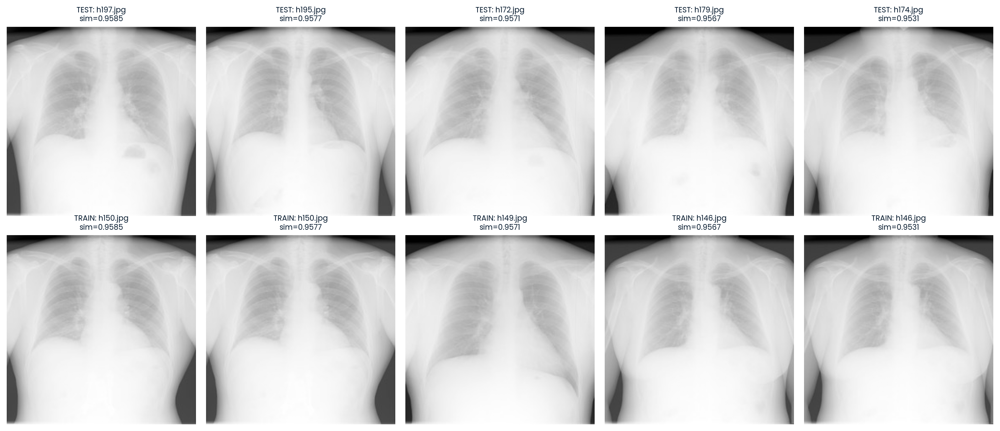

In [38]:
# Eyeball the closest pairs
# If these look like the same radiograph twice, the train/test split is compromised.

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5), squeeze=False)
for c, i in enumerate(top[:5]):
    for r, (path, tag) in enumerate([(test_df["filename"].values[i], "TEST"),
                                     (df["filename"].values[best_j[i]], "TRAIN")]):
        ax = axes[r][c]; ax.axis("off")
        with Image.open(path) as im:
            ax.imshow(np.asarray(im.convert("L")), cmap="gray")
        ax.set_title(f"{tag}: {os.path.basename(path)}\nsim={best_s[i]:.4f}", fontsize=8)
fig.tight_layout(); fig.savefig("near_duplicate_pairs.png", dpi=130, bbox_inches="tight"); plt.show()


In [39]:
from PIL import Image
def stats(p):
   with Image.open(p) as im:
       w, h = im.size
       a = np.asarray(im.convert("L"), dtype=np.float32)
   return {"w": w, "h": h, "aspect": w / h, "mean": a.mean(), "std": a.std(),
           "p05": np.percentile(a, 5), "p95": np.percentile(a, 95),
           "bytes": os.path.getsize(p)}

**Which class is off?** Breaking the mean grey level down by class shows the TB images agree
across both folders (143.9 vs 144.2). It's the healthy test images that stand apart — about
50 grey levels brighter than healthy training images.

In [40]:
for name, frame in [("TRAIN", df), ("TEST", test_df)]:
   S = pd.DataFrame([stats(p) for p in frame["filename"]])
   y = frame["label_idx"].values
   print(f"\n--- {name} (n={len(y)}) ---")
   for col in S.columns:
       a = roc_auc_score(y, S[col])
       print(f"  {col:7s}: AUC {max(a, 1-a):.3f}")


--- TRAIN (n=302) ---
  w      : AUC 0.500
  h      : AUC 0.500
  aspect : AUC 0.500
  mean   : AUC 0.566
  std    : AUC 0.628
  p05    : AUC 0.612
  p95    : AUC 0.556
  bytes  : AUC 0.633

--- TEST (n=100) ---
  w      : AUC 0.500
  h      : AUC 0.500
  aspect : AUC 0.500
  mean   : AUC 0.996
  std    : AUC 0.889
  p05    : AUC 0.846
  p95    : AUC 0.989
  bytes  : AUC 0.934


If you can tell healthy from TB just by how bright the image is, the problem is in the
data, not the model. Brightness, contrast and file size have nothing to do with
tuberculosis, so if they separate the classes, a model will learn them instead of the
disease.

Each statistic is used on its own as a one-feature classifier, scored by AUC (flipped to
≥0.5, since it doesn't matter which direction it points). The two folders are scored
separately: if something separates the classes in one folder but not the other, that's a
difference in how the images were taken or saved, not biology.

In [41]:
## Confounder check — can simple image statistics tell the classes apart?

for name, frame in [("TRAIN", df), ("TEST", test_df)]:
    m = np.array([np.asarray(Image.open(p).convert("L"), dtype=np.float32).mean()
                  for p in frame["filename"]])
    y = frame["label_idx"].values
    print(f"{name}: healthy {m[y==0].mean():.1f}±{m[y==0].std():.1f} | "
          f"tb {m[y==1].mean():.1f}±{m[y==1].std():.1f}")

TRAIN: healthy 147.2±13.3 | tb 143.9±8.4
TEST: healthy 196.8±12.8 | tb 144.2±9.7


**What came out.** The training folder is fine — everything lands between 0.50 and 0.63,
which is close to guessing. The test folder is not. Mean brightness on its own gets
**AUC 0.996**, p95 gets 0.989, file size 0.934, contrast 0.889. 

The TB images match across both folders (143.9 vs 144.2). It's the healthy test images
that are off — about 50 grey levels brighter than healthy training images, and about 4.6
standard deviations away from test TB, so the two test classes hardly overlap at all.

That explains the thing that didn't add up earlier: each fold model scores 0.55–0.68 on
its own validation fold but 0.97–0.997 on the test set, and one fold scores 0.003 — it
learned the task backwards. Brightness is only a weak signal in the training data
(AUC 0.566), so which way a fold picks it up is more or less luck. On the test set that
same weak detector turns into a near-perfect one.

If the folders just differed in exposure, normalizing every image on its own would wipe
that out and the test set would still be usable. So we try two ways and compare them to
the raw images:

- **z-score** — subtract the image's own mean, divide by its own standard deviation. This
  wipes out absolute brightness and contrast completely.
- **equalize** — histogram equalization (PIL), which flattens out the spread of brightness
  levels in each image.

Both work on one image at a time, so nothing leaks between images.


In [42]:
# Does normalizing each image fix it?

from PIL import ImageOps

def stats_after(p, mode):
    im = Image.open(p).convert("L")
    if mode == "equalize":
        im = ImageOps.equalize(im)          
    a = np.asarray(im, dtype=np.float32)
    if mode == "zscore":
        a = (a - a.mean()) / (a.std() + 1e-8)
    return {"p05": np.percentile(a, 5), "p25": np.percentile(a, 25),
            "p50": np.percentile(a, 50), "p75": np.percentile(a, 75),
            "p95": np.percentile(a, 95)}

for mode in ["raw", "zscore", "equalize"]:
    print(f"\n=== {mode} ===")
    for name, frame in [("TRAIN", df), ("TEST", test_df)]:
        S = pd.DataFrame([stats_after(p, mode) for p in frame["filename"]])
        y = frame["label_idx"].values
        aucs = {c: max(roc_auc_score(y, S[c]), 1 - roc_auc_score(y, S[c])) for c in S}
        print(f"  {name}: " + "  ".join(f"{c} {v:.3f}" for c, v in aucs.items()))


=== raw ===
  TRAIN: p05 0.612  p25 0.575  p50 0.546  p75 0.519  p95 0.556
  TEST: p05 0.846  p25 0.998  p50 0.997  p75 0.996  p95 0.989

=== zscore ===
  TRAIN: p05 0.545  p25 0.521  p50 0.509  p75 0.502  p95 0.507
  TEST: p05 0.860  p25 0.999  p50 0.984  p75 0.950  p95 0.994

=== equalize ===
  TRAIN: p05 0.558  p25 0.534  p50 0.553  p75 0.546  p95 0.521
  TEST: p05 0.560  p25 0.725  p50 0.798  p75 0.803  p95 0.872


**It doesn't fix it.**


After z-score, p25 is still at **0.999**. So the classes don't just differ in how bright
or how contrasty they are — the whole *shape* of the brightness distribution is different,
and z-score doesn't touch shape. Equalizing gets rid of most of the gap but still leaves
0.80–0.87, against a baseline of about 0.55. That fits with the bright healthy images
having blown-out white areas: once detail is clipped, equalization can't bring it back.

**So the test folder is out.** Normalizing won't save it, and every test-set number from
earlier was measuring this artifact, not tuberculosis. The numbers we can trust are the
out-of-fold ones from the 302 training images: ResNet50 0.827, DenseNet121 0.795,
custom CNN 0.580.

## Adversarial validation — are the two folders the same kind of data?

Instead of asking "healthy or TB?", this asks "which folder did this image come from?".
If a classifier can't tell, the two sets are the same kind of data and could be pooled.
If it can tell, they're different populations and shouldn't be mixed.

The features are intensity statistics, image and file size, and a coarse 8x8 thumbnail.
The AUC is cross-validated, so overfitting can't inflate it. Run it per class.

**What came out.**

| comparison | AUC |
|---|---|
| all train vs all test | 0.793 |
| train healthy vs test healthy | **0.977** |
| train TB vs test TB | 0.626 |

The healthy comparison at 0.977 is the problem we already know about, and it doubles as a
check that the test itself works. The TB images sit much closer together — 0.626 is a long
way from 0.977.

**But does 0.626 actually mean anything?** With 151 images against 50, even two random
halves of the same pile won't score exactly 0.5. So we measured that: split the training TB
images at random into groups of the same size, run the same check, 100 times over.

Random splits of the same data give a mean of 0.503, a 95% range of [0.378, 0.630], and a
highest run of 0.655. Only 4 of the 100 runs reached 0.626, so **p = 0.04**. It sits just
inside the 95% range but above all but four of the runs — right on the line.

**What it means.** There's a small shift between training TB and test TB images, right at
the edge of what this check can see. Nothing like the healthy case, but real. So the 50 test
TB images stay out of the training pool: adding 50 images of one class from a slightly
different source is exactly how you grow the next confounder.

In [43]:
# Adversarial validation
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


def feature_vector(p):
    """Intensity statistics, file properties and a coarse 8x8 thumbnail."""
    im = Image.open(p).convert("L")
    w, h = im.size
    a = np.asarray(im, dtype=np.float32)
    thumb = np.asarray(im.resize((8, 8)), dtype=np.float32).ravel()
    stats = [a.mean(), a.std(), *np.percentile(a, [1, 5, 25, 50, 75, 95, 99]),
             w, h, os.path.getsize(p)]
    return np.concatenate([stats, thumb])


X_tr = np.stack([feature_vector(p) for p in df["filename"]])
X_te = np.stack([feature_vector(p) for p in test_df["filename"]])
y_tr, y_te = df["label_idx"].values, test_df["label_idx"].values


def adversarial(Xa, Xb, n_splits=5):
    """Cross-validated AUC for predicting which folder a sample came from."""
    X = np.vstack([Xa, Xb])
    origin = np.r_[np.zeros(len(Xa)), np.ones(len(Xb))]
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5))
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    prob = cross_val_predict(model, X, origin, cv=cv, method="predict_proba")[:, 1]
    return roc_auc_score(origin, prob)


print("Adversarial validation — 'which folder is this from?'")
print("  ~0.5 = indistinguishable (poolable)   ~1.0 = different sources\n")
print(f"  all train vs all test        : {adversarial(X_tr, X_te):.3f}")
print(f"  train HEALTHY vs test HEALTHY: {adversarial(X_tr[y_tr==0], X_te[y_te==0]):.3f}")
print(f"  train TB      vs test TB     : {adversarial(X_tr[y_tr==1], X_te[y_te==1]):.3f}")

Adversarial validation — 'which folder is this from?'
  ~0.5 = indistinguishable (poolable)   ~1.0 = different sources

  all train vs all test        : 0.793
  train HEALTHY vs test HEALTHY: 0.977
  train TB      vs test TB     : 0.626


In [44]:
rng = np.random.default_rng(SEED)
X_tb_train = X_tr[y_tr == 1]
n_test_tb = int((y_te == 1).sum())
observed = adversarial(X_tr[y_tr == 1], X_te[y_te == 1])

null_aucs = []
for _ in range(100):
    idx = rng.permutation(len(X_tb_train))
    null_aucs.append(adversarial(X_tb_train[idx[n_test_tb:]], X_tb_train[idx[:n_test_tb]]))

null_aucs = np.array(null_aucs)
p_value = (null_aucs >= observed).mean()

print("Null baseline — training TB split against itself, same group sizes (100 runs):")
print(f"  mean {null_aucs.mean():.3f} | 95% range "
      f"[{np.percentile(null_aucs, 2.5):.3f}, {np.percentile(null_aucs, 97.5):.3f}]")
print(f"  highest null run: {null_aucs.max():.3f}")
print(f"\nObserved train TB vs test TB: {observed:.3f}")
print(f"Empirical p-value: {p_value:.3f}  "
      f"({int((null_aucs >= observed).sum())} of 100 null runs matched or beat it)")

Null baseline — training TB split against itself, same group sizes (100 runs):
  mean 0.503 | 95% range [0.378, 0.630]
  highest null run: 0.655

Observed train TB vs test TB: 0.626
Empirical p-value: 0.040  (4 of 100 null runs matched or beat it)


## Honest evaluation — out-of-fold predictions on the 302 training images

The test folder is out, so the results come from cross-validation on the clean training
set instead. These predictions were already there: every image was predicted by the one
fold model that never saw it during training, so nothing here is fitted on what it scores.

Cross-validation over all 302 images is also the better choice at this sample size.
Holding out 60 for a test set would mean training on 242 and reporting a number measured
on 60 — a wider error bar for no gain.

One thing to be careful about. If you pick a cutoff on the same predictions you then
score, sensitivity and specificity come out a little too good. So the cutoff is picked
per fold on the other four and applied to the held-out one. ROC-AUC and PR-AUC need no
cutoff at all and are the primary numbers here; the rest follow from it.


In [45]:
# Honest evaluation
oof_sets = {
    "ResNet50":    "oof.npz",
    "DenseNet121": "dense_oof.npz",
    "Custom CNN":  "baseline_oof.npz",
}

y = df["label_idx"].values.astype(float)

fold_of = np.zeros(len(df), dtype=int)
for k, (_, va) in enumerate(skf.split(df["filename"], df["label_idx"])):
    fold_of[va] = k


def nested_threshold_pred(prob, y, fold_of, recall_level=0.90):
    """Cutoff picked on the other four folds, applied to the held-out one."""
    pred = np.zeros(len(y), dtype=int)
    used = []
    for k in np.unique(fold_of):
        inner, outer = fold_of != k, fold_of == k
        t = get_fixed_threshold(y[inner], prob[inner], recall_level)
        used.append(t)
        pred[outer] = (prob[outer] >= t).astype(int)
    return pred, used


def bootstrap_ci_fixed(y, prob, pred, n=2000, seed=SEED):
    """CIs for predictions that are already fixed — no re-thresholding inside."""
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keys = ["roc_auc", "pr_auc", "sensitivity", "specificity", "ppv", "npv"]
    acc = {k: [] for k in keys}
    for _ in range(n):
        idx = np.concatenate([rng.choice(pos, len(pos), True),
                              rng.choice(neg, len(neg), True)])
        m = clinical_metrics(y[idx], prob[idx], pred[idx])
        for k in keys:
            acc[k].append(m[k])
    return {k: [float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))]
            for k, v in acc.items()}


oof_prob, oof_pred, summary = {}, {}, {}
for name, path in oof_sets.items():
    d = np.load(path)
    prob = d["oof_prob"]
    assert np.array_equal(d["oof_true"].astype(int), y.astype(int)), f"{name}: labels misaligned"

    pred, thrs = nested_threshold_pred(prob, y, fold_of)
    res = clinical_metrics(y, prob, pred)
    ci = bootstrap_ci_fixed(y, prob, pred)
    oof_prob[name], oof_pred[name] = prob, pred

    tn, fp, fn, tp = res["confmat"]
    print(f"\n=== {name} (n={len(y)}, fold cutoffs {min(thrs):.3f}-{max(thrs):.3f}) ===")
    print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
    for k in ["roc_auc", "pr_auc", "sensitivity", "specificity", "ppv", "npv"]:
        print(f"  {k:12s}: {res[k]:.3f}  [{ci[k][0]:.3f}-{ci[k][1]:.3f}]")

    summary[name] = {k: f"{res[k]:.2f} [{ci[k][0]:.2f}-{ci[k][1]:.2f}]"
                     for k in ["roc_auc", "pr_auc", "sensitivity", "specificity", "ppv", "npv"]}

oof_table = pd.DataFrame(summary).T
oof_table.to_csv("oof_results.csv")
oof_table


=== ResNet50 (n=302, fold cutoffs 0.138-0.202) ===
TN=70 FP=81 FN=16 TP=135
  roc_auc     : 0.827  [0.778-0.872]
  pr_auc      : 0.856  [0.815-0.895]
  sensitivity : 0.894  [0.841-0.940]
  specificity : 0.464  [0.384-0.543]
  ppv         : 0.625  [0.587-0.664]
  npv         : 0.814  [0.738-0.886]

=== DenseNet121 (n=302, fold cutoffs 0.226-0.310) ===
TN=43 FP=108 FN=19 TP=132
  roc_auc     : 0.795  [0.739-0.845]
  pr_auc      : 0.831  [0.786-0.872]
  sensitivity : 0.874  [0.815-0.927]
  specificity : 0.285  [0.212-0.358]
  ppv         : 0.550  [0.521-0.581]
  npv         : 0.694  [0.586-0.797]

=== Custom CNN (n=302, fold cutoffs 0.431-0.444) ===
TN=37 FP=114 FN=15 TP=136
  roc_auc     : 0.580  [0.513-0.643]
  pr_auc      : 0.578  [0.521-0.640]
  sensitivity : 0.901  [0.848-0.940]
  specificity : 0.245  [0.179-0.311]
  ppv         : 0.544  [0.518-0.571]
  npv         : 0.712  [0.591-0.824]


,roc_auc,pr_auc,sensitivity,specificity,ppv,npv
ResNet50,0.83 [0.78-0.87],0.86 [0.81-0.89],0.89 [0.84-0.94],0.46 [0.38-0.54],0.62 [0.59-0.66],0.81 [0.74-0.89]
DenseNet121,0.80 [0.74-0.85],0.83 [0.79-0.87],0.87 [0.81-0.93],0.28 [0.21-0.36],0.55 [0.52-0.58],0.69 [0.59-0.80]
Custom CNN,0.58 [0.51-0.64],0.58 [0.52-0.64],0.90 [0.85-0.94],0.25 [0.18-0.31],0.54 [0.52-0.57],0.71 [0.59-0.82]


## Where to set the cutoff

One cutoff hides the trade-off, so here are several. The table shows what each model gives
at a range of sensitivity targets, and Youden's J picks the point where sensitivity and
specificity together are at their best.

**What came out.** At its best balance ResNet50 catches 70% of TB cases and correctly
clears 85% of healthy ones. DenseNet121 sits at 0.62 / 0.87, trading sensitivity for
specificity. The custom CNN manages 0.85 / 0.31 — even at its own best point it flags most
healthy people as TB.

| model | sensitivity | specificity | cutoff |
|---|---|---|---|
| ResNet50 | 0.702 | 0.854 | 0.451 |
| DenseNet121 | 0.616 | 0.868 | 0.587 |
| Custom CNN | 0.854 | 0.311 | 0.444 |

This is also where the earlier "recall ≥ 0.90" rule stops making sense. It was set when the
models looked like they scored 0.97, and back then 90% sensitivity was cheap. At AUC 0.83
it costs nearly all the specificity — ResNet50 ends up flagging 81 of 151 healthy images.
At this level of performance you can't have both, and the ROC curve shows how much one
costs the other.

One thing worth noticing on the curve: both pretrained models rise almost vertically at the
left edge, so about 20% of TB cases get picked out with no false positives at all. That
points to a different job than screening — flag that fifth automatically and send the rest
through the normal workflow.

Best balance (Youden's J):
  ResNet50     sens 0.702  spec 0.854  at 0.451
  DenseNet121  sens 0.616  spec 0.868  at 0.587
  Custom CNN   sens 0.854  spec 0.311  at 0.444


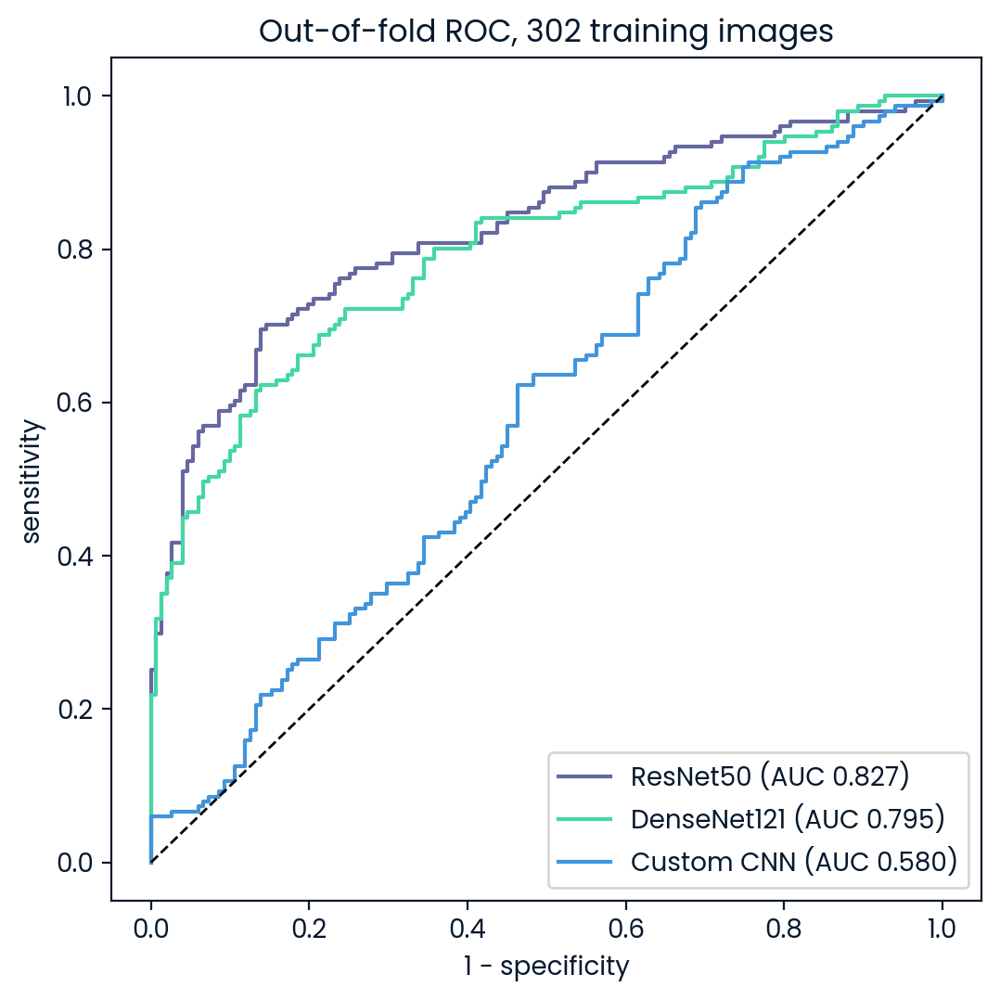

,model,target_sens,sensitivity,specificity,threshold
0,ResNet50,0.95,0.954,0.212,0.065
1,ResNet50,0.90,0.901,0.450,0.147
2,ResNet50,0.85,0.854,0.523,0.221
3,ResNet50,0.80,0.808,0.662,0.282
4,ResNet50,0.70,0.702,0.854,0.451
5,DenseNet121,0.95,0.954,0.159,0.204
6,DenseNet121,0.90,0.907,0.265,0.261
7,DenseNet121,0.85,0.854,0.464,0.362
8,DenseNet121,0.80,0.801,0.642,0.445
9,DenseNet121,0.70,0.702,0.768,0.523


In [46]:
## Where to set the cutoff
from sklearn.metrics import roc_curve

rows = []
for name, prob in oof_prob.items():
    fpr, tpr, thr = roc_curve(y, prob)
    for target in [0.95, 0.90, 0.85, 0.80, 0.70]:
        i = int(np.argmax(tpr >= target))
        rows.append({"model": name, "target_sens": target,
                     "sensitivity": round(float(tpr[i]), 3),
                     "specificity": round(float(1 - fpr[i]), 3),
                     "threshold": round(float(thr[i]), 3)})
op = pd.DataFrame(rows)
op.to_csv("operating_points.csv", index=False)

print("Best balance (Youden's J):")
for name, prob in oof_prob.items():
    fpr, tpr, thr = roc_curve(y, prob)
    j = int(np.argmax(tpr - fpr))
    print(f"  {name:12s} sens {tpr[j]:.3f}  spec {1-fpr[j]:.3f}  at {thr[j]:.3f}")

plt.figure(figsize=(5.5, 5.5))
for name, prob in oof_prob.items():
    fpr, tpr, _ = roc_curve(y, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("1 − specificity"); plt.ylabel("sensitivity")
plt.title("Out-of-fold ROC, 302 training images")
plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig("roc_oof.png", dpi=130); plt.show()
op

## Are the models actually different from each other?

Overlapping confidence intervals don't settle this. Two models can overlap and still differ
reliably, because they're scored on the same images and share the same noise. So this
resamples the same images for both models and builds an interval on the difference itself.
If that interval excludes zero, the difference is real.

**What came out.**

| comparison | AUC difference | real? |
|---|---|---|
| ResNet50 − DenseNet121 | +0.032 [−0.006, +0.073] | no |
| ResNet50 − Custom CNN | +0.249 [+0.167, +0.325] | yes |
| DenseNet121 − Custom CNN | +0.216 [+0.139, +0.288] | yes |

The two pretrained backbones can't be told apart. Both beat training from scratch by a wide
margin, and that gap sits well clear of zero.

So the question this project started with — is transfer learning worth it here? — has a
clear answer. With 302 images a network trained from scratch never gets off the ground
(AUC 0.58). Which pretrained backbone you pick matters far less than whether you use one.

In [47]:
# Are the models actually different from each other
def paired_auc_diff(y, pa, pb, n=2000, seed=SEED):
    """Same resampled images for both models, so the shared noise cancels out."""
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    diffs = []
    for _ in range(n):
        idx = np.concatenate([rng.choice(pos, len(pos), True),
                              rng.choice(neg, len(neg), True)])
        diffs.append(roc_auc_score(y[idx], pa[idx]) - roc_auc_score(y[idx], pb[idx]))
    d = np.array(diffs)
    return float(d.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))


rows = []
for a, b in [("ResNet50", "DenseNet121"), ("ResNet50", "Custom CNN"),
             ("DenseNet121", "Custom CNN")]:
    m, lo, hi = paired_auc_diff(y, oof_prob[a], oof_prob[b])
    sig = "yes" if (lo > 0 or hi < 0) else "no"
    print(f"{a} − {b}: {m:+.3f} [{lo:+.3f}, {hi:+.3f}]   significant: {sig}")
    rows.append({"comparison": f"{a} - {b}", "auc_diff": round(m, 3),
                 "ci_low": round(lo, 3), "ci_high": round(hi, 3), "significant": sig})

pd.DataFrame(rows).to_csv("model_comparison_oof.csv", index=False)

ResNet50 − DenseNet121: +0.032 [-0.006, +0.073]   significant: no
ResNet50 − Custom CNN: +0.249 [+0.167, +0.325]   significant: yes
DenseNet121 − Custom CNN: +0.216 [+0.139, +0.288]   significant: yes


## Where the model looks — on images it never trained on

The earlier attention maps were drawn on test images, so they go out along with everything
else from that folder. This is the honest version: every image is explained by the fold
model that held it out, so nothing is explaining what it memorised.

Two numbers go with the pictures:

- **border heat** — how much attention lands in the outer 15% of the frame. A flat,
  uninformative map scores about 0.51, so lower means attention pulled in toward the middle
  of the chest.
- **heat vs brightness** — how the attention map lines up with pixel brightness. On a
  radiograph bone and soft tissue are bright and air-filled lung is dark, so a negative
  number means attention sits in the lung fields and not on bone or body outline.

Expect less from these than from the earlier maps. Those came from models that looked like
they scored 0.98 because they were reading an artifact; at AUC 0.83 the picture is messier,
and that's the real one.

**What came out.** Border heat 0.488, against a flat-map reference of 0.51 — attention is
pulled inward, but only just. Heat vs brightness −0.346, so it does sit in the darker lung
fields rather than on bone and body outline.

Both are weaker than the same numbers measured on the test set earlier (0.379 and −0.447).
That's the point: those maps looked sharper because the model had a brightness shortcut to
hold onto. These are what a 0.83 AUC model actually looks like — pointed in the right
direction, not sharply enough to hand a radiologist.

ResNet50 on held-out TB images (n=20):
  border heat        : 0.488   (uniform reference 0.51)
  heat vs brightness : -0.346


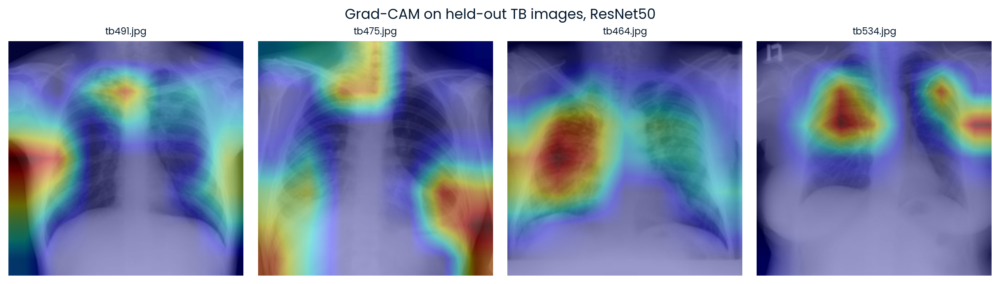

In [48]:
## Where the model looks - on images it never trained on?
tb_idx = np.where(y == 1)[0]
sample = np.random.default_rng(SEED).choice(tb_idx, 20, replace=False)
paths_tr = df["filename"].values

grad_models = {}
for k in range(N_SPLITS):
    m = tf.keras.models.load_model(f"best_model_fold{k}.keras", compile=False)
    grad_models[k] = build_grad_model(m, (*IMG_SIZE, 3), last_conv=RESNET_LAST_CONV)

border, bright = [], []
for i in sample:
    gm = grad_models[fold_of[i]]          # the fold model that held this image out
    raw, batch = resnet_load(paths_tr[i])
    heat = cam_from(gm, batch)
    border.append(border_fraction(heat))
    bright.append(heat_intensity_corr(heat, raw))

print(f"ResNet50 on held-out TB images (n={len(sample)}):")
print(f"  border heat        : {np.mean(border):.3f}   (uniform reference 0.51)")
print(f"  heat vs brightness : {np.nanmean(bright):+.3f}")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, i in zip(axes, sample[:4]):
    raw, batch = resnet_load(paths_tr[i])
    ax.imshow(raw, cmap="gray")
    ax.imshow(cam_from(grad_models[fold_of[i]], batch), cmap="jet", alpha=0.4)
    ax.axis("off"); ax.set_title(os.path.basename(paths_tr[i]), fontsize=8)
fig.suptitle("Grad-CAM on held-out TB images, ResNet50")
fig.tight_layout(); fig.savefig("gradcam_oof.png", dpi=130, bbox_inches="tight"); plt.show()
